## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements

import sys
from pathlib import Path
import gc

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Load Data and Measurement

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

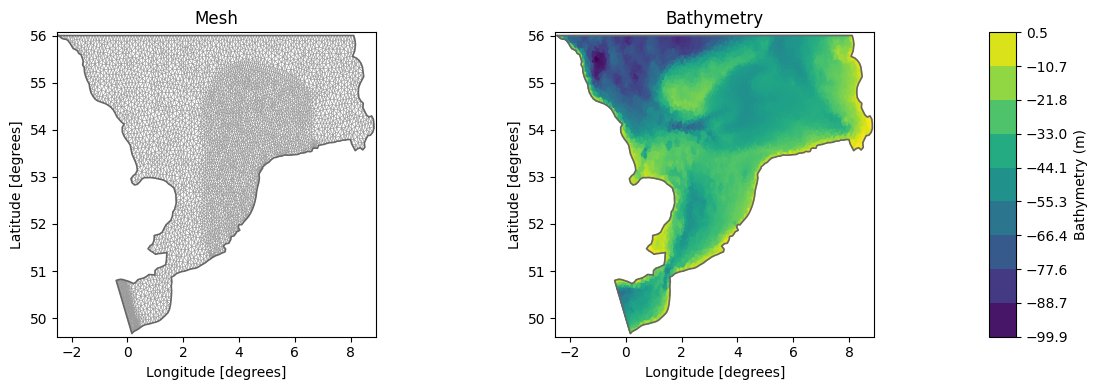

In [4]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

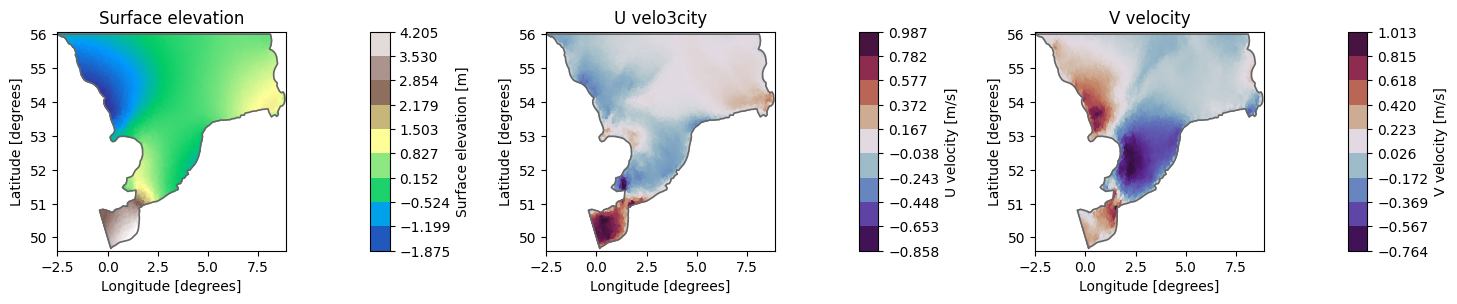

In [5]:
# plot a simulation
ds = dfs.read(time = slice("2022-01-01", "2023-10-01"))

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velo3city", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


## Available Sensors

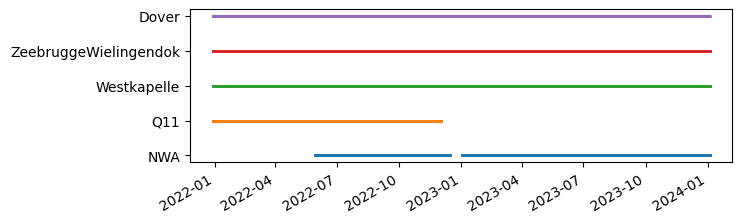

In [6]:
# sensor coverage

wllist = get_wl_point_obs()
#altlist = get_altimetry_obs()

high_fidelity = ["Dover", "ZeebruggeWielingendok", "Westkapelle", "NWA", "Q11"]

alllist = wllist #+ altlist
alllist = [obs for obs in alllist if obs.name in high_fidelity]
ms.plotting.temporal_coverage(alllist)
plt.show()

Total stations: 5
Stations with full temporal coverage: 2
Intermittent stations: 3


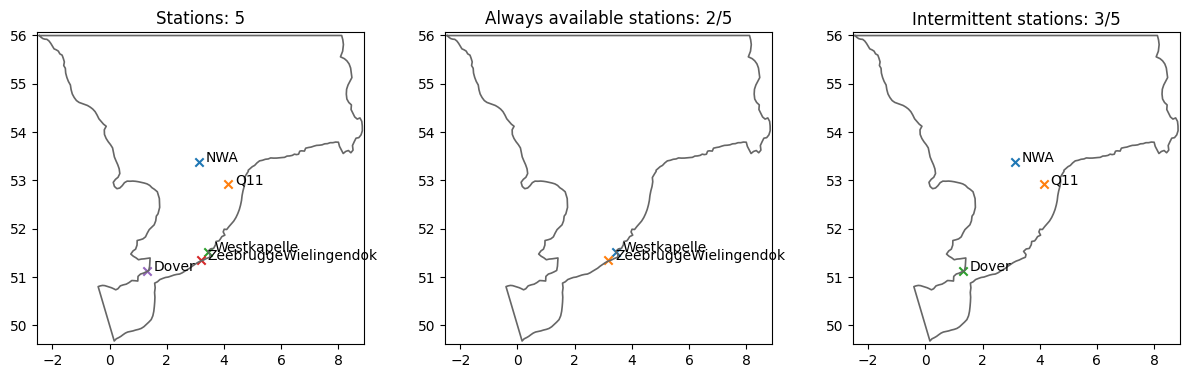

In [7]:
# Select stations with full temporal coverage

stations = []
availables = []
intermittent = []
for i in range(len(alllist)):
    stations.append(alllist[i])
    if ds.time.isin(alllist[i].time).all():
        availables.append(alllist[i])
    else:
        intermittent.append(alllist[i])

print(f"Total stations: {len(stations)}")
print(f"Stations with full temporal coverage: {len(availables)}")
print(f"Intermittent stations: {len(intermittent)}")

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(availables, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(availables)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intermittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [8]:
# Extract water level measurements

measurements = extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr)

In [9]:
# Extract the values and convert to torch tensors

# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory
del dsH, dsU, dsV

H shape: torch.Size([30672, 8533])
U shape: torch.Size([30672, 8533])
V shape: torch.Size([30672, 8533])
Measurements shape: torch.Size([30672, 5])


In [10]:
ERRORS = []

In [11]:
# Extract measurements for always-available stations only
av_indices = [stations.index(s) for s in availables]
measurements_av = measurements[:, av_indices]

time_steps, _ = measurements_av.shape

# Count NaNs for intermittent stations
intermittent_indices = [stations.index(s) for s in intermittent]
nan_counts_intermittent = np.isnan(measurements[:, intermittent_indices].numpy()).sum(axis=0)

# Build a clean coverage table and sort by coverage percentage
rows = []
for i, s in enumerate(intermittent):
    ok_count = int(time_steps - nan_counts_intermittent[i])
    nan_count = int(nan_counts_intermittent[i])
    coverage = 100 * ok_count / time_steps
    rows.append({
        "station": s.name,
        "ok": ok_count,
        "nans": nan_count,
        "coverage_%": round(coverage, 1),
    })
coverage_df = pd.DataFrame(rows).sort_values("coverage_%", ascending=False).reset_index(drop=True)

print(f"Intermittent stations ({len(intermittent)}):")
display(coverage_df.style.format({"ok": "{:,}", "nans": "{:,}", "coverage_%": "{:.1f}"}))

Intermittent stations (3):


,station,ok,nans,coverage_%
0,NWA,"22,230","8,442",72.5
1,Q11,"15,900","14,772",51.8
2,Dover,"14,899","15,773",48.6


## Idea T.0: Only Available Sensors

In [12]:
# Keep only sensors that never contain NaNs over time
nan_sensor_mask = torch.isnan(measurements).any(dim=0)
measurements_av = measurements[:, ~nan_sensor_mask]

kept_sensor_indices = torch.where(~nan_sensor_mask)[0]
removed_sensor_indices = torch.where(nan_sensor_mask)[0]

# print the shape of the arrays
print("\nAfter selecting always-available stations only:")
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements_av.shape)


After selecting always-available stations only:
H shape: torch.Size([30672, 8533])
U shape: torch.Size([30672, 8533])
V shape: torch.Size([30672, 8533])
Measurements shape: torch.Size([30672, 2])


Nuber of nan values in measurements after imputation: 0 



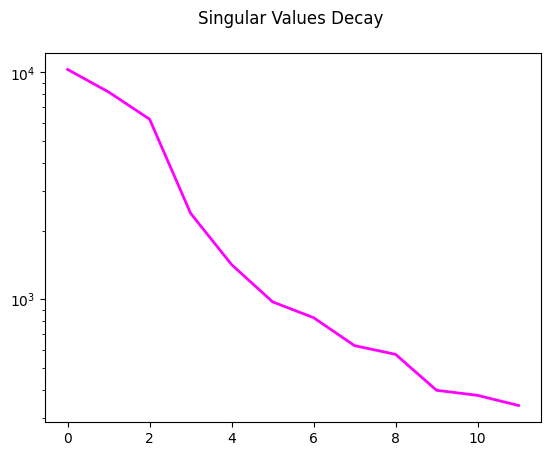

Residual energy of Surface elevation after keeping 12 modes: 0.1667 %


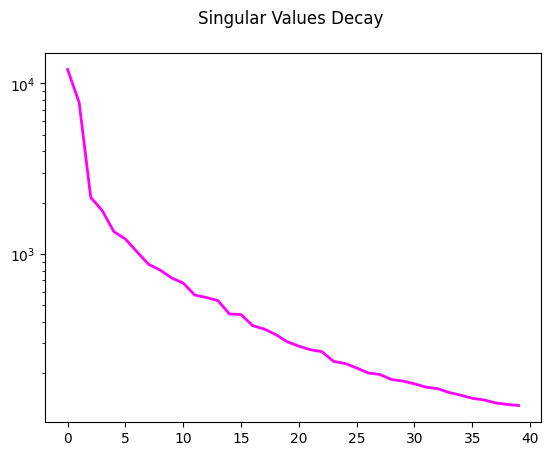

Residual energy of U velocity after keeping 40 modes: 0.1929 %


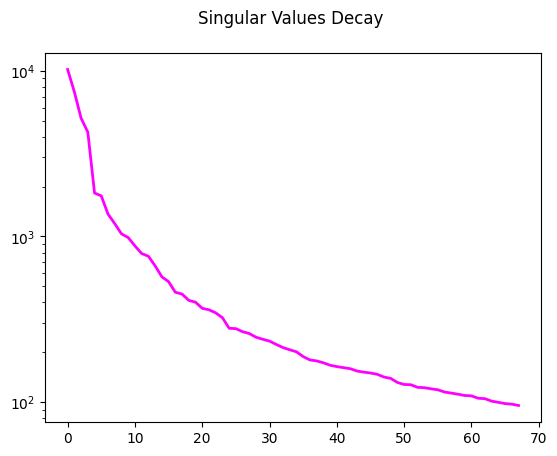

Residual energy of V velocity after keeping 68 modes: 0.1844 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([26071, 24, 2]) -> torch.Size([26071, 120])
Val:	 torch.Size([0, 24, 2]) -> torch.Size([0, 120])
Test:	 torch.Size([4601, 24, 2]) -> torch.Size([4601, 120])

Input shape for the model: 2
Output shape for the model: 120


In [13]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.85, val_size = 0.0, test_size = 0.15)

# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = 12, measurements = measurements_av, verbose = True)
manager.add_data(U, id = "U velocity", compress = 40, verbose = True)
manager.add_data(V, id = "V velocity", compress = 68, verbose = True)

# prepare datasets
train_dataset, _, test_dataset = manager.prepare(verbose = True); val_dataset = None

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements_av.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Starting training...


Training: 100%|██████████| 250/250 [34:56<00:00,  8.38s/it, Train Loss=0.0047, LR=0.00e+00]

Training completed without validation set (early stopping disabled).


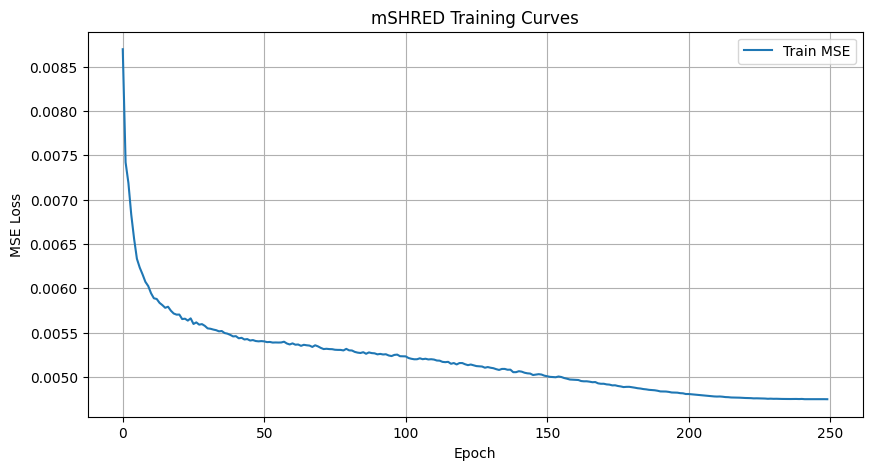

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795


In [14]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels = False
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, _ = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=250,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=250,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
# validation curve disabled (no validation set)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
# validation metrics disabled (no validation set)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(T.0) only available sensors",
    "train-mse": float(train_mse),
    # val-mse disabled (no validation set),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    # val-mre disabled (no validation set),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_0_only_available_sensors.png


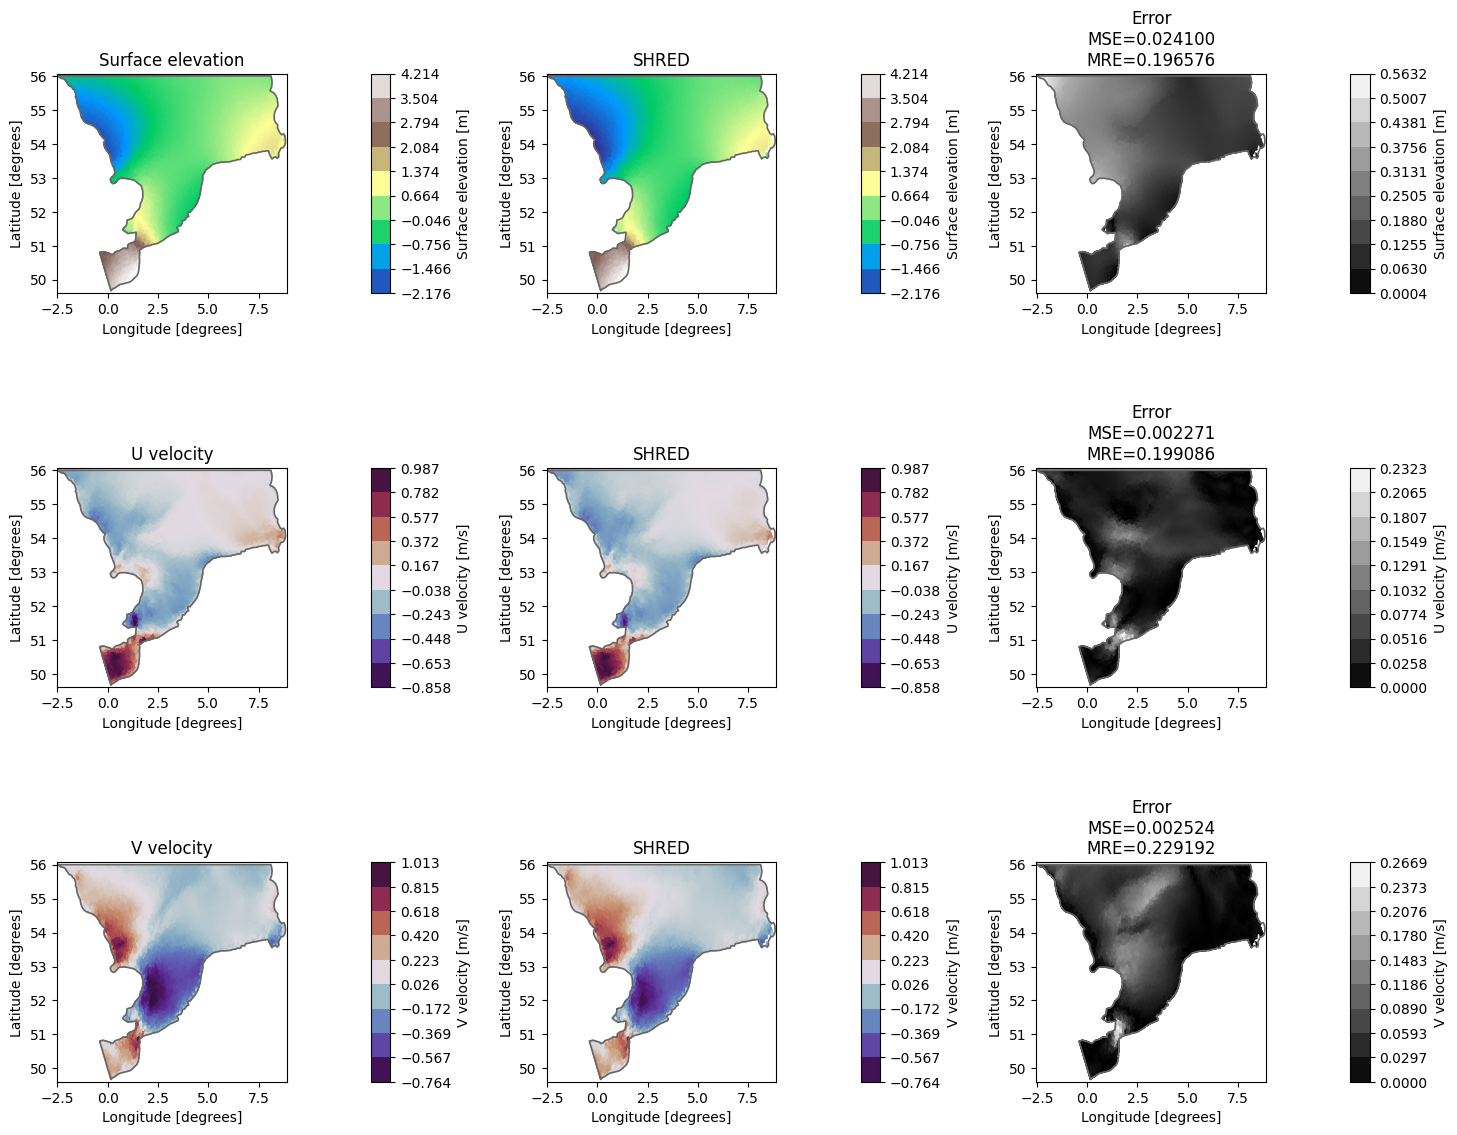

134279

In [15]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_0_only_available_sensors")

del engine, test_reconstruction, ds_shred, ds_error, mshred
gc.collect()

## Idea S.0: Only Available Sensors

Starting training...


Training: 100%|██████████| 250/250 [10:05<00:00,  2.42s/it, Train Loss=0.0045, LR=0.00e+00]

Training completed without validation set (early stopping disabled).


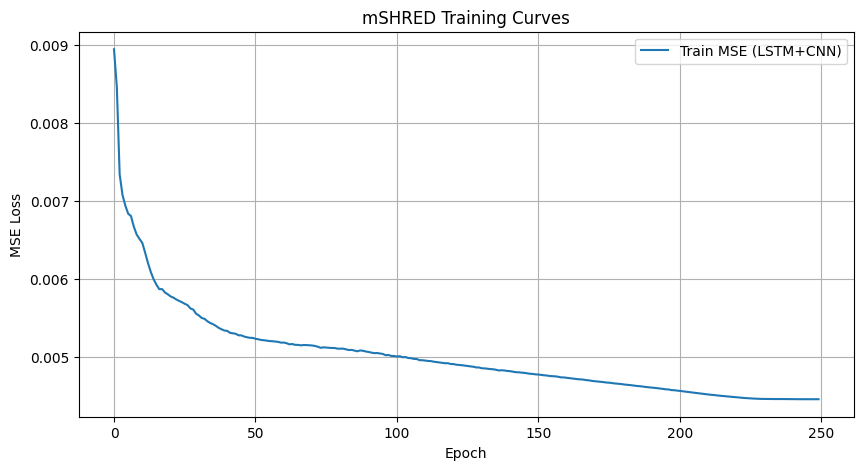

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280


In [16]:

# mSHRED TRAINING 
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, _ = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=250,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=250,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
# validation curve disabled (no validation set)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
# validation metrics disabled (no validation set)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.0) only available sensors",
    "train-mse": float(train_mse_shred),
    # val-mse disabled (no validation set),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    # val-mre disabled (no validation set),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_0_only_available_sensors.png


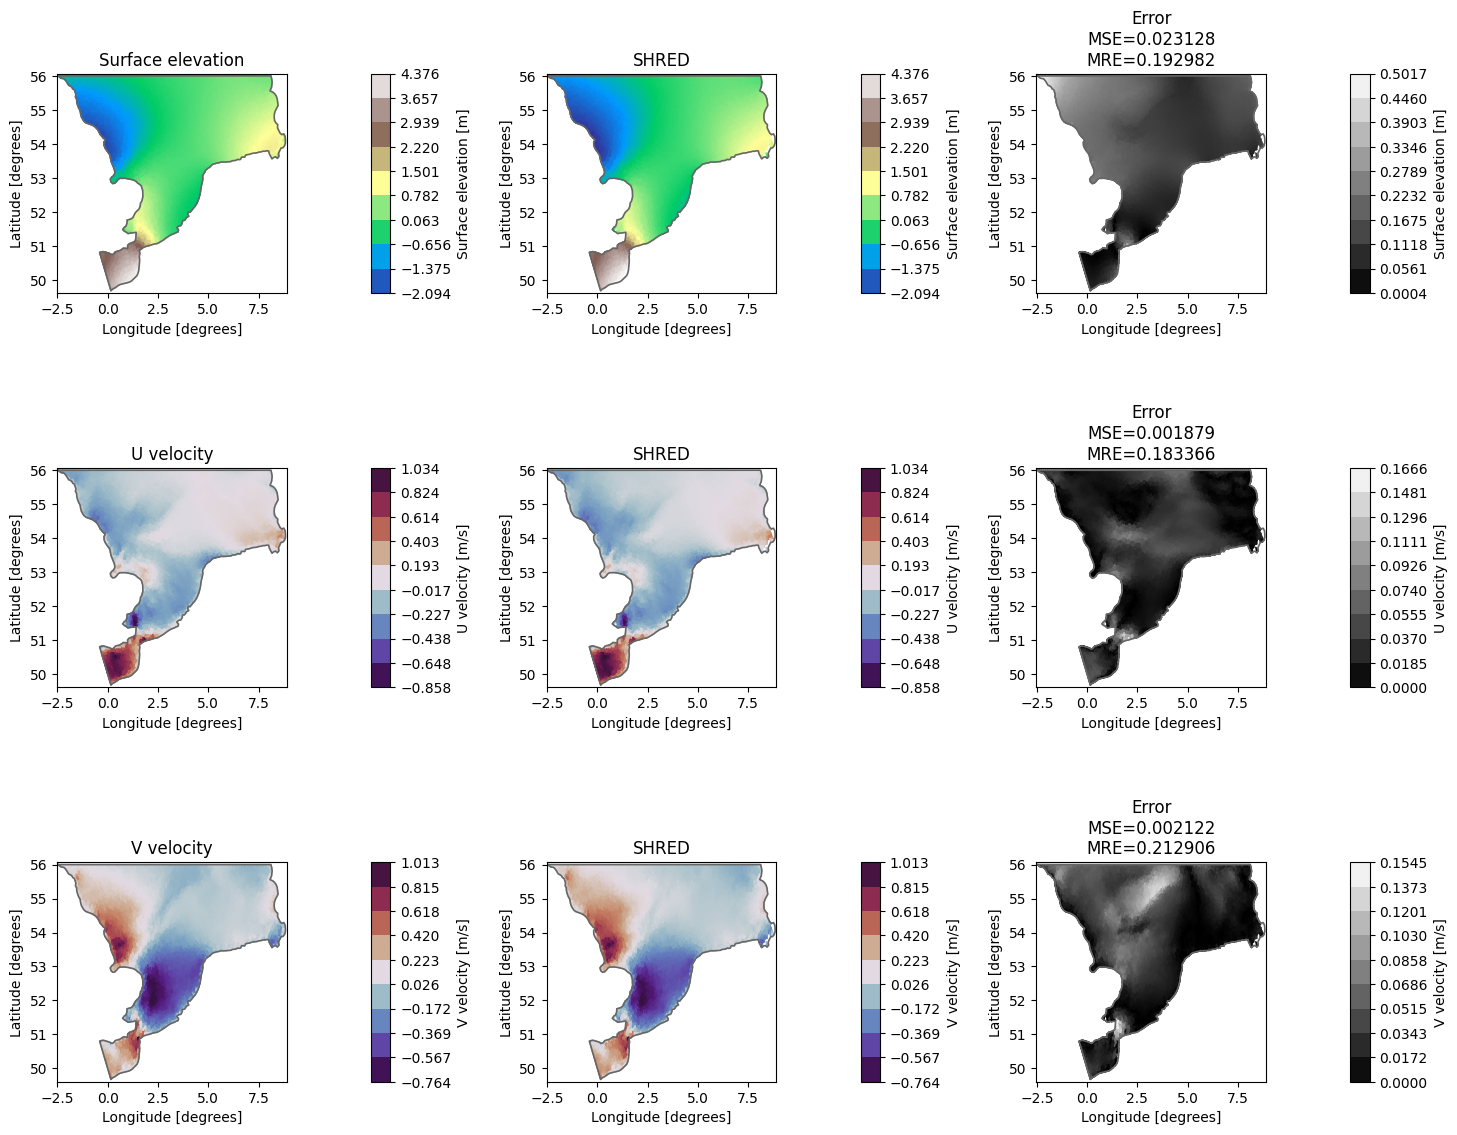

134224

In [17]:
# SHRED RECONSTRUCTION (Idea S.0)
engine_shred = SHREDEngine(manager, mshred)
test_reconstruction_shred = engine_shred.sensor_to_reconstruction_dataset(test_dataset)
ds_shred_s0, ds_error_s0 = plot_shred_reconstruction(test_reconstruction_shred, ds, geom, title_suffix="S_0_only_available_sensors")

del engine_shred, test_reconstruction_shred, ds_shred_s0, ds_error_s0, mshred, manager
gc.collect()

## Idea T.1.A: Median imputer

In [18]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.85, val_size = 0.0, test_size = 0.15)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="median"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets (no validation set)
train_dataset, _, test_dataset = manager.prepare(verbose = True)
val_dataset = None

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1667 %
Residual energy of U velocity after keeping 40 modes: 0.1929 %
Residual energy of V velocity after keeping 68 modes: 0.1844 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([26071, 24, 5]) -> torch.Size([26071, 120])
Val:	 torch.Size([0, 24, 5]) -> torch.Size([0, 120])
Test:	 torch.Size([4601, 24, 5]) -> torch.Size([4601, 120])

Input shape for the model: 5
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 250/250 [29:54<00:00,  7.18s/it, Train Loss=0.0045, LR=0.00e+00]

Training completed without validation set (early stopping disabled).


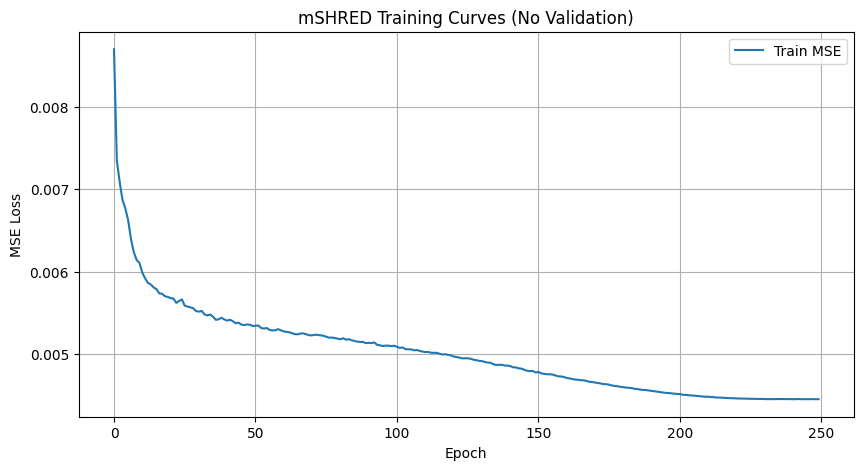

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760


In [19]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, _ = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=250,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=250,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves (No Validation)')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(T.1.A) median imputation for missing sensors",
    "train-mse": float(train_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_A_median_imputation.png


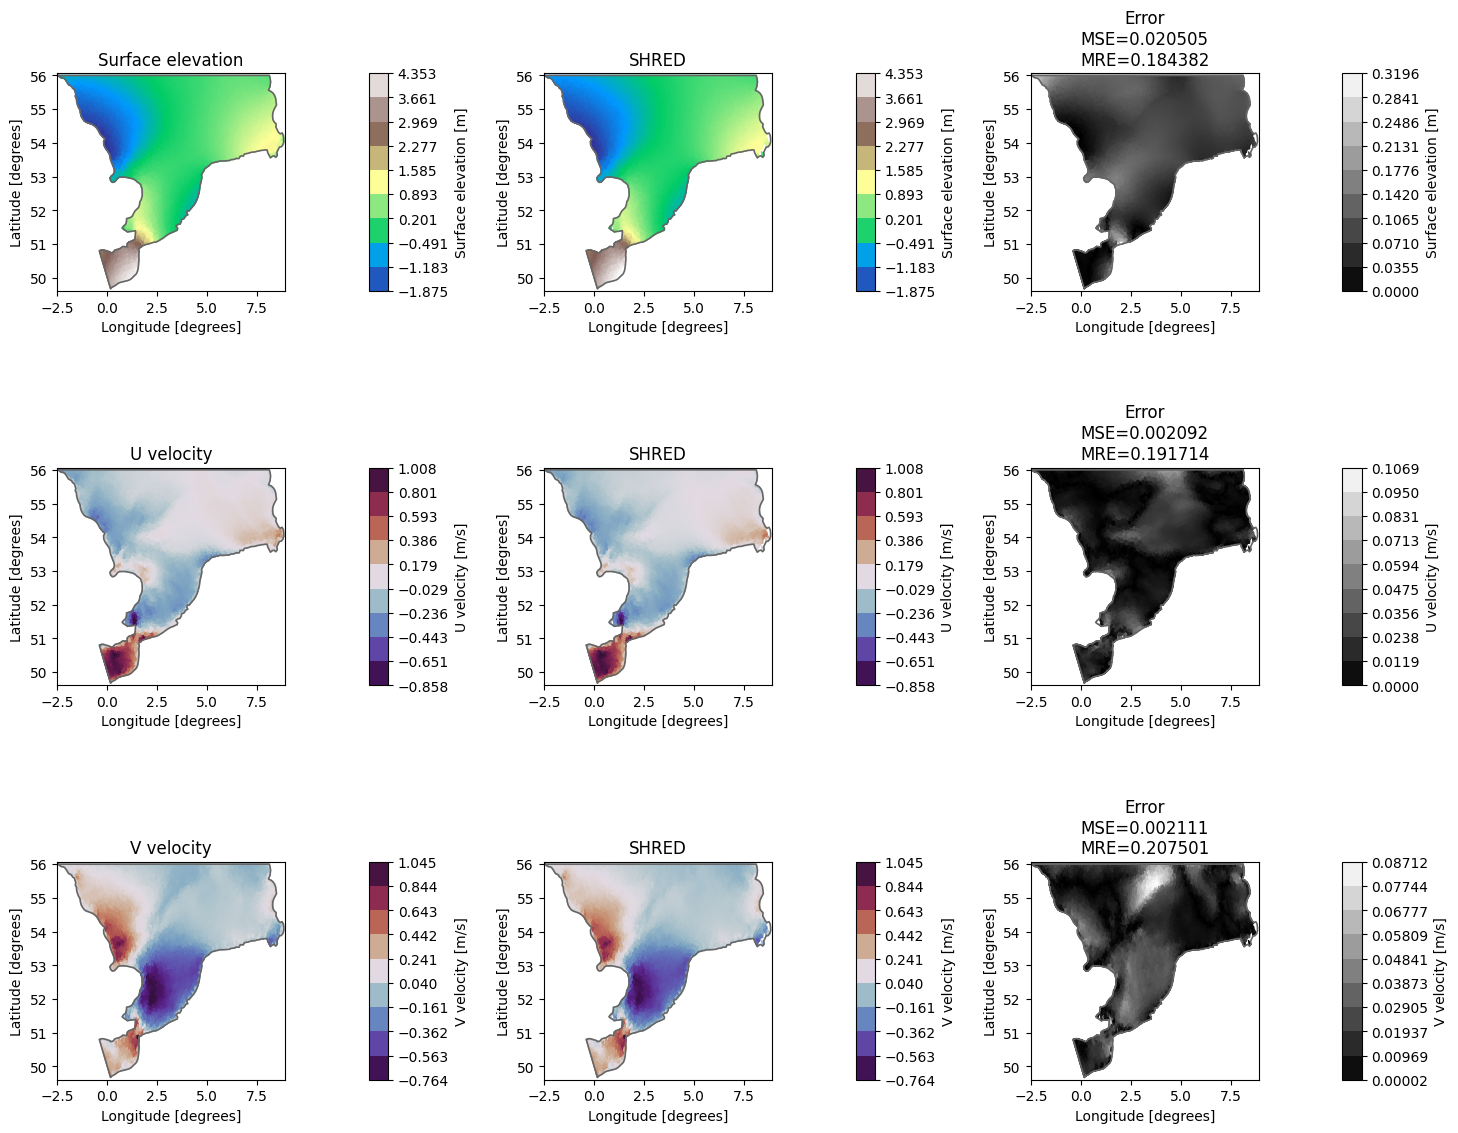

134269

In [20]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_A_median_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager
gc.collect()

## Idea T.1.B: Mean imputer

In [21]:
# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.85, val_size = 0.0, test_size = 0.15)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="mean"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, _, test_dataset = manager.prepare(verbose = True); val_dataset = None

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1667 %
Residual energy of U velocity after keeping 40 modes: 0.1929 %
Residual energy of V velocity after keeping 68 modes: 0.1844 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([26071, 24, 5]) -> torch.Size([26071, 120])
Val:	 torch.Size([0, 24, 5]) -> torch.Size([0, 120])
Test:	 torch.Size([4601, 24, 5]) -> torch.Size([4601, 120])

Input shape for the model: 5
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 250/250 [29:56<00:00,  7.18s/it, Train Loss=0.0045, LR=0.00e+00]

Training completed without validation set (early stopping disabled).


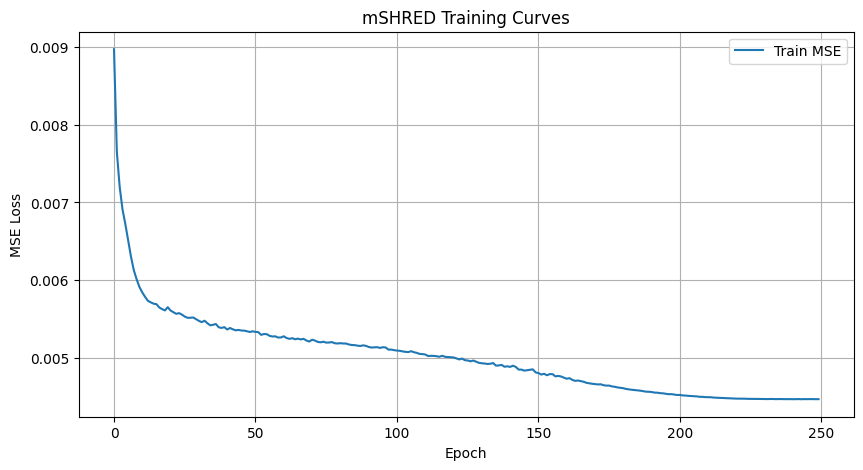

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004472,0.004213,0.133182,0.127428


In [22]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, _ = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=250,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=250,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
# validation curve disabled (no validation set)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
# validation metrics disabled (no validation set)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(T.1.B) mean imputation for missing sensors",
    "train-mse": float(train_mse),
    # val-mse disabled (no validation set),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    # val-mre disabled (no validation set),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_B_mean_imputation.png


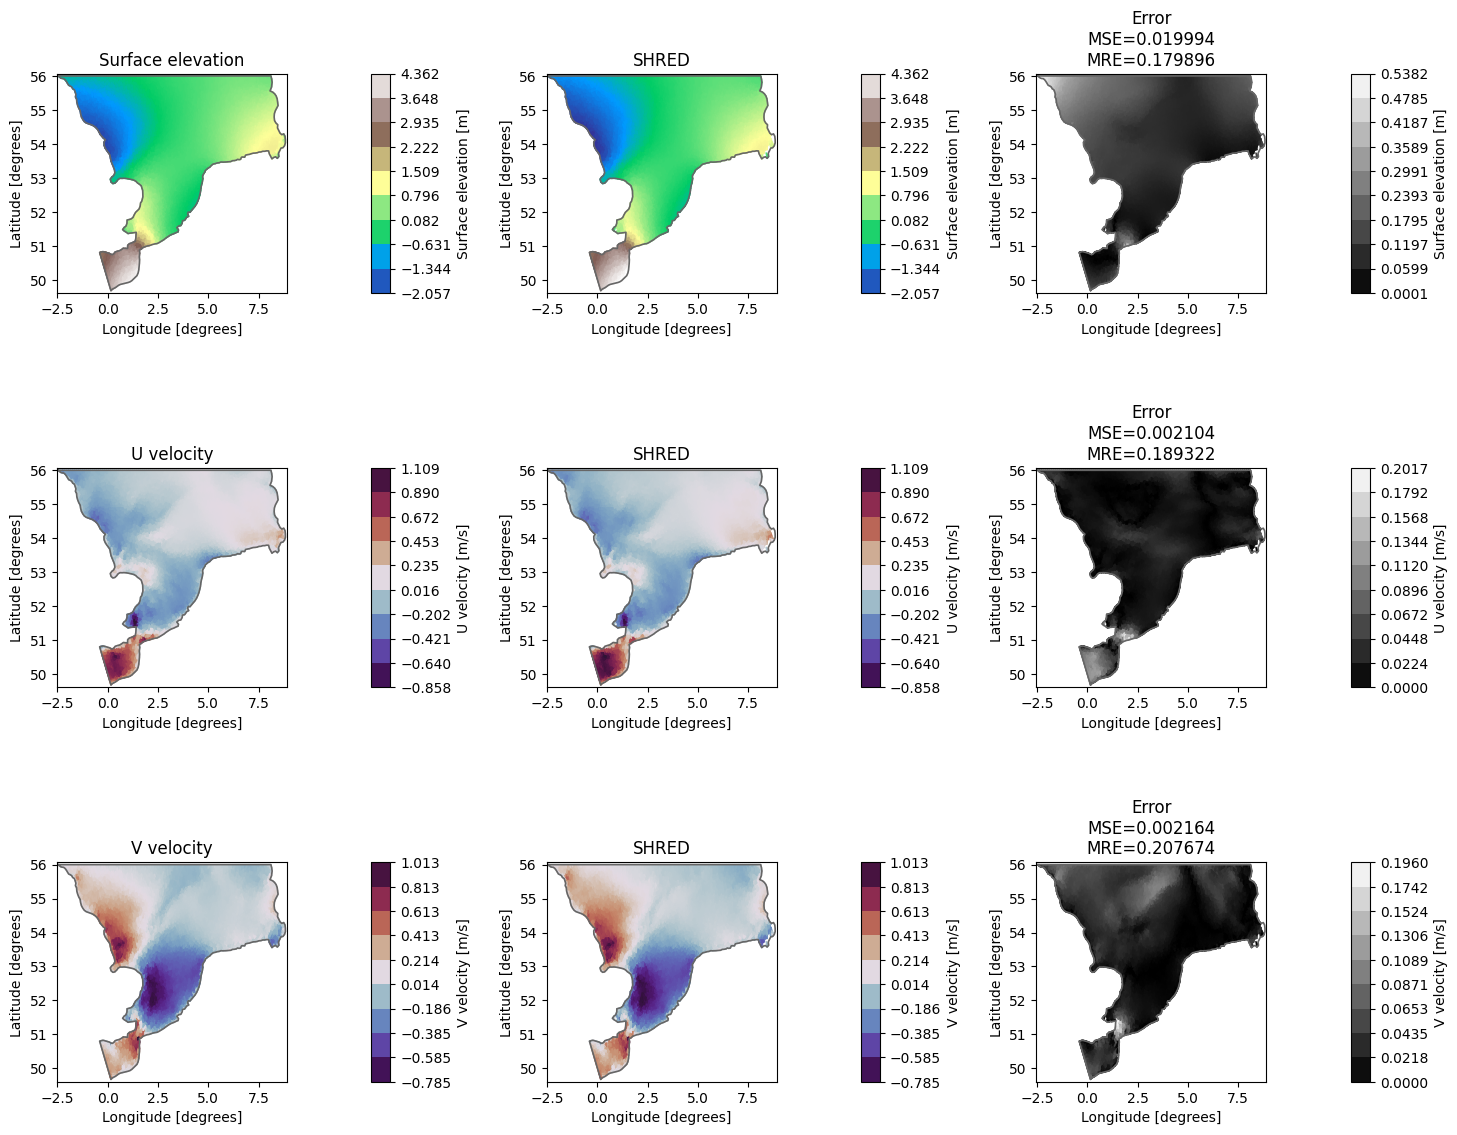

134269

In [23]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_B_mean_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager
gc.collect()

## Idea T.1.C: Last value imputer

In [24]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.85, val_size = 0.0, test_size = 0.15)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="last_value"
 )
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, _, test_dataset = manager.prepare(verbose = True); val_dataset = None

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1667 %
Residual energy of U velocity after keeping 40 modes: 0.1929 %
Residual energy of V velocity after keeping 68 modes: 0.1844 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([26071, 24, 5]) -> torch.Size([26071, 120])
Val:	 torch.Size([0, 24, 5]) -> torch.Size([0, 120])
Test:	 torch.Size([4601, 24, 5]) -> torch.Size([4601, 120])

Input shape for the model: 5
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 250/250 [29:50<00:00,  7.16s/it, Train Loss=0.0044, LR=0.00e+00]

Training completed without validation set (early stopping disabled).


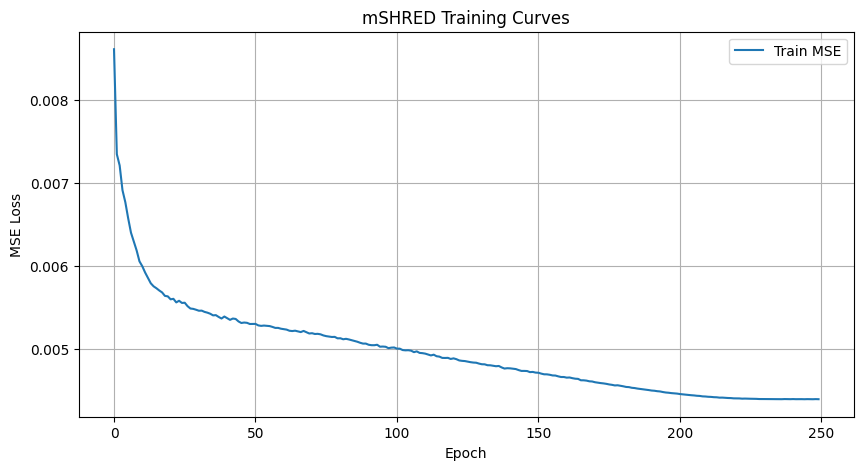

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004472,0.004213,0.133182,0.127428
4,(mSHRED): TR + MLP,(T.1.C) last value imputation for missing sensors,0.004390,0.004239,0.132071,0.128126


In [25]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, _ = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=250,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=250,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
# validation curve disabled (no validation set)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
# validation metrics disabled (no validation set)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(T.1.C) last value imputation for missing sensors",
    "train-mse": float(train_mse),
    # val-mse disabled (no validation set),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    # val-mre disabled (no validation set),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_C_last_value_imputation.png


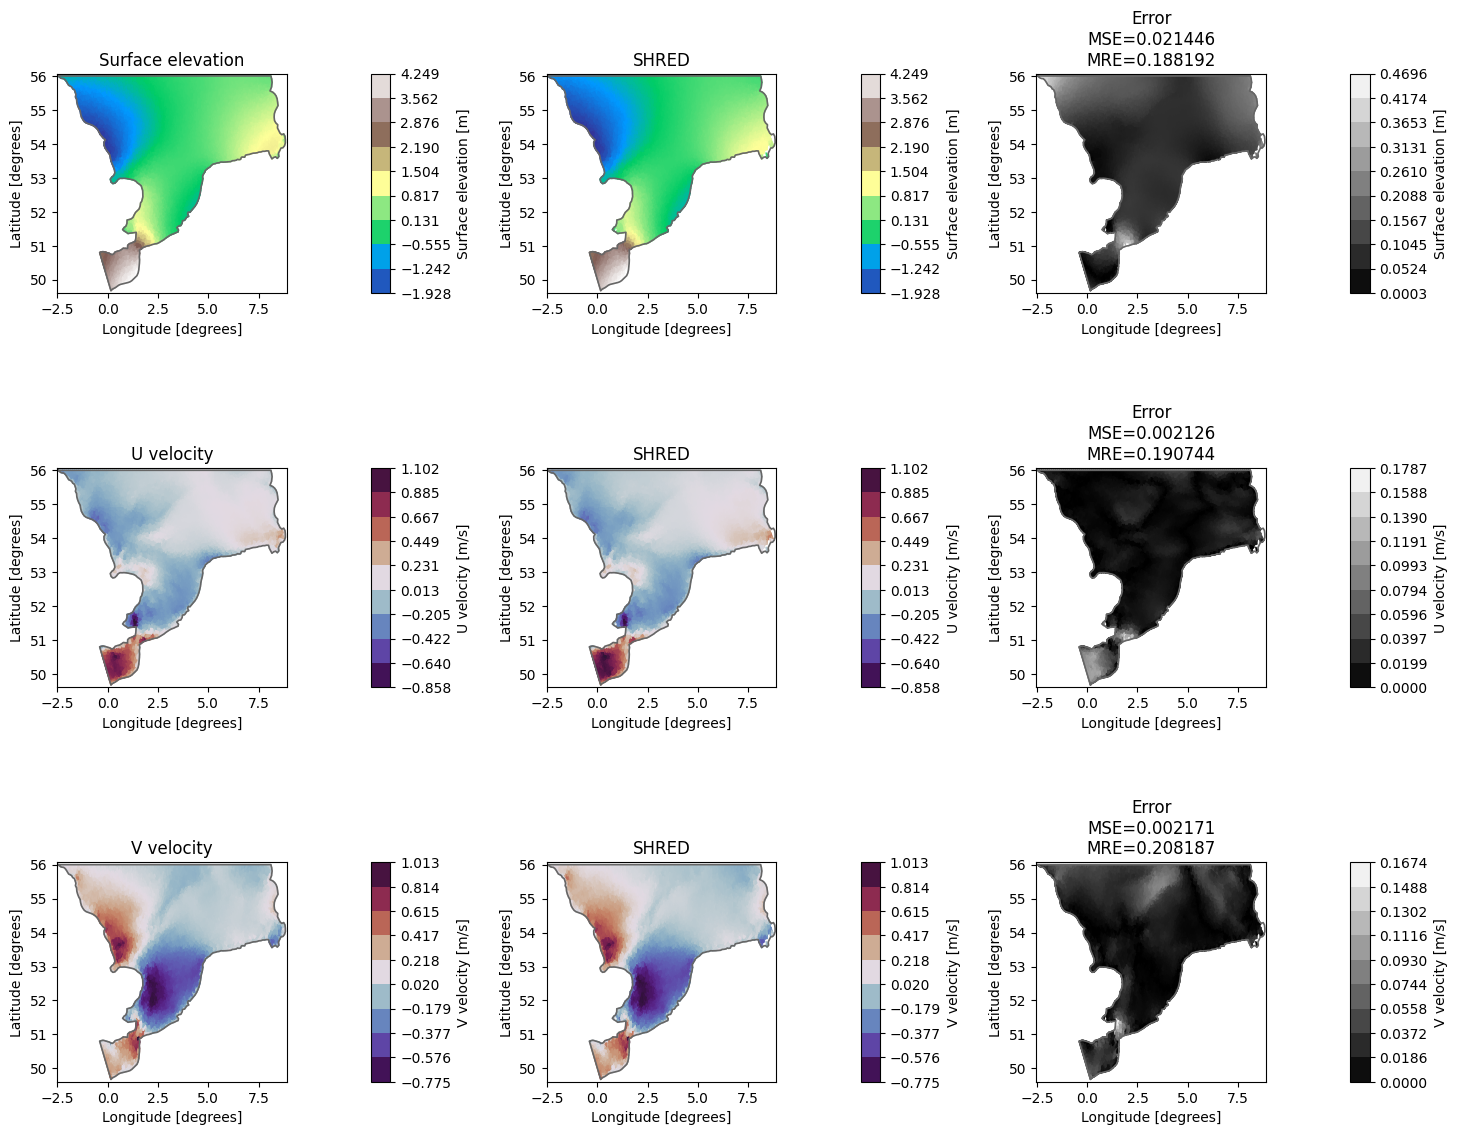

134284

In [26]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_C_last_value_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager
gc.collect()

## Idea 2.A: GRUD

In [27]:

# Data manager
lags = 24
manager = DataManager(lags = lags, train_size = 0.85, val_size = 0.0, test_size = 0.15)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, _, test_dataset, X_mean = manager.prepare(verbose = True, masking_type="grud"); val_dataset = None

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 38987 

Residual energy of Surface elevation after keeping 12 modes: 0.1667 %
Residual energy of U velocity after keeping 40 modes: 0.1929 %
Residual energy of V velocity after keeping 68 modes: 0.1844 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([26071, 4, 24, 5]) -> torch.Size([26071, 120])
Val:	 torch.Size([0, 4, 24, 5]) -> torch.Size([0, 120])
Test:	 torch.Size([4601, 4, 24, 5]) -> torch.Size([4601, 120])

Input shape for the model: 5
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 250/250 [27:38<00:00,  6.63s/it, Train Loss=0.0045, LR=0.00e+00]

Training completed without validation set (early stopping disabled).


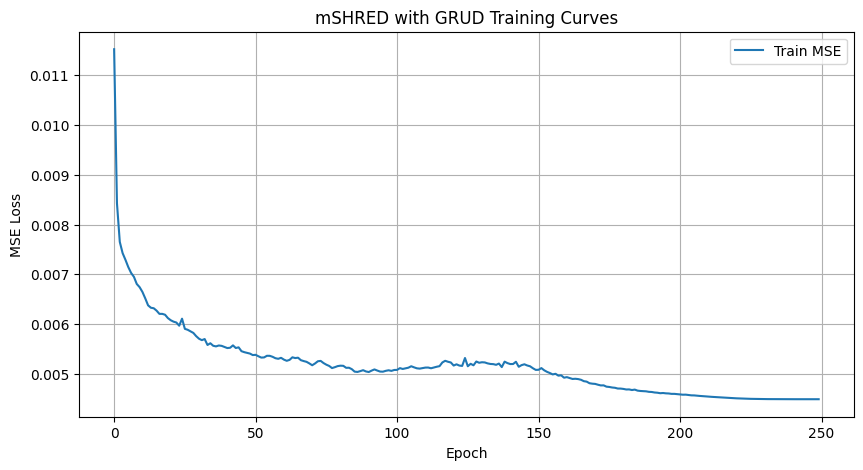

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004472,0.004213,0.133182,0.127428
4,(mSHRED): TR + MLP,(T.1.C) last value imputation for missing sensors,0.004390,0.004239,0.132071,0.128126
5,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004493,0.004284,0.133687,0.129290


In [28]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="grud",
    input_size=nn_input_shape,
    hidden_size=32,
    X_mean=X_mean,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, _ = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=250,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=250,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
# validation curve disabled (no validation set)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED with GRUD Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
# validation metrics disabled (no validation set)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): GRUD + CNN",
    "type" : "(2.A) GRUD masking",
    "train-mse": float(train_mse),
    # val-mse disabled (no validation set),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    # val-mre disabled (no validation set),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_2_A_GRUD_masking.png


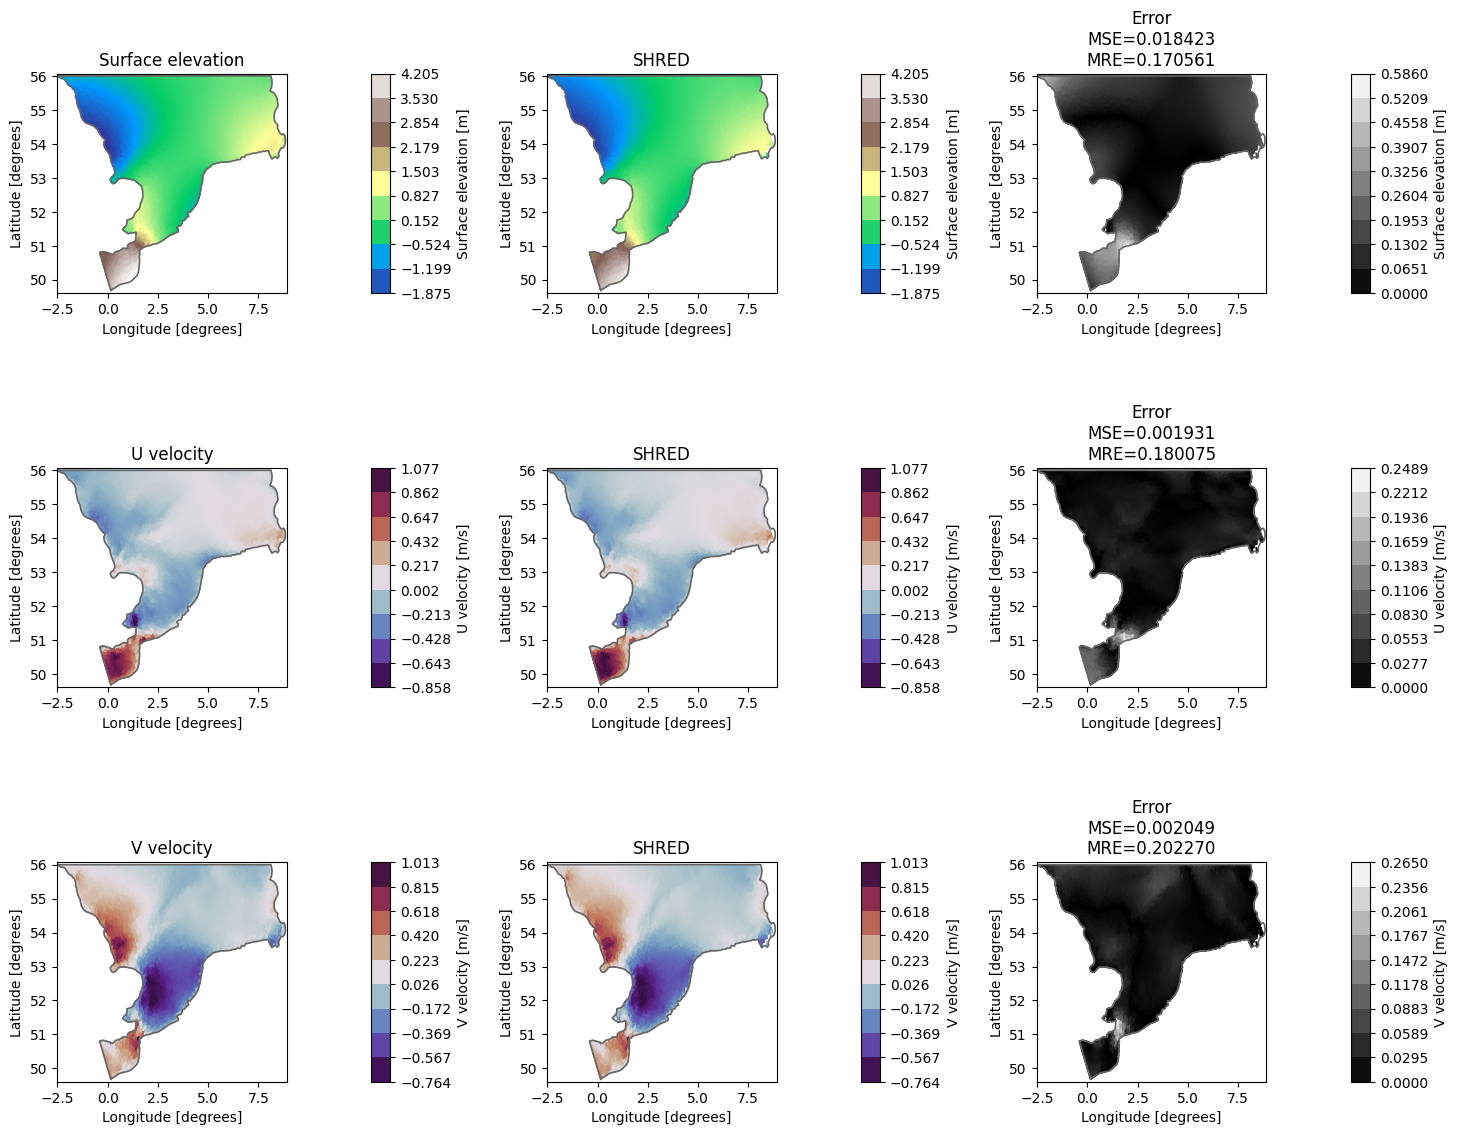

134204

In [29]:
# mSHRED RECONSTRUCTION

engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="2_A_GRUD_masking")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred
gc.collect()

## Idea 2.B: Attn AGRUD


Starting training...


Training: 100%|██████████| 250/250 [44:04<00:00, 10.58s/it, Train Loss=0.0045, LR=0.00e+00]

Training completed without validation set (early stopping disabled).


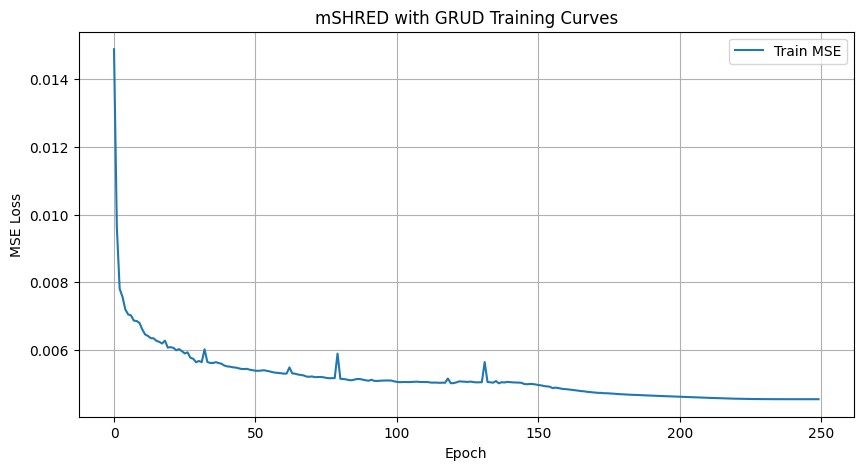

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004472,0.004213,0.133182,0.127428
4,(mSHRED): TR + MLP,(T.1.C) last value imputation for missing sensors,0.004390,0.004239,0.132071,0.128126
5,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004493,0.004284,0.133687,0.129290
6,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004537,0.004387,0.134571,0.131390


In [30]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="att_grud",
    input_size=nn_input_shape,
    hidden_size=32,
    X_mean=X_mean,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, _ = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=250,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=250,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
# validation curve disabled (no validation set)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED with GRUD Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
# validation metrics disabled (no validation set)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): attnGRUD + CNN",
    "type" : "(2.B) GRUD masking",
    "train-mse": float(train_mse),
    # val-mse disabled (no validation set),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    # val-mre disabled (no validation set),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_2_B_attnGRUD_masking.png


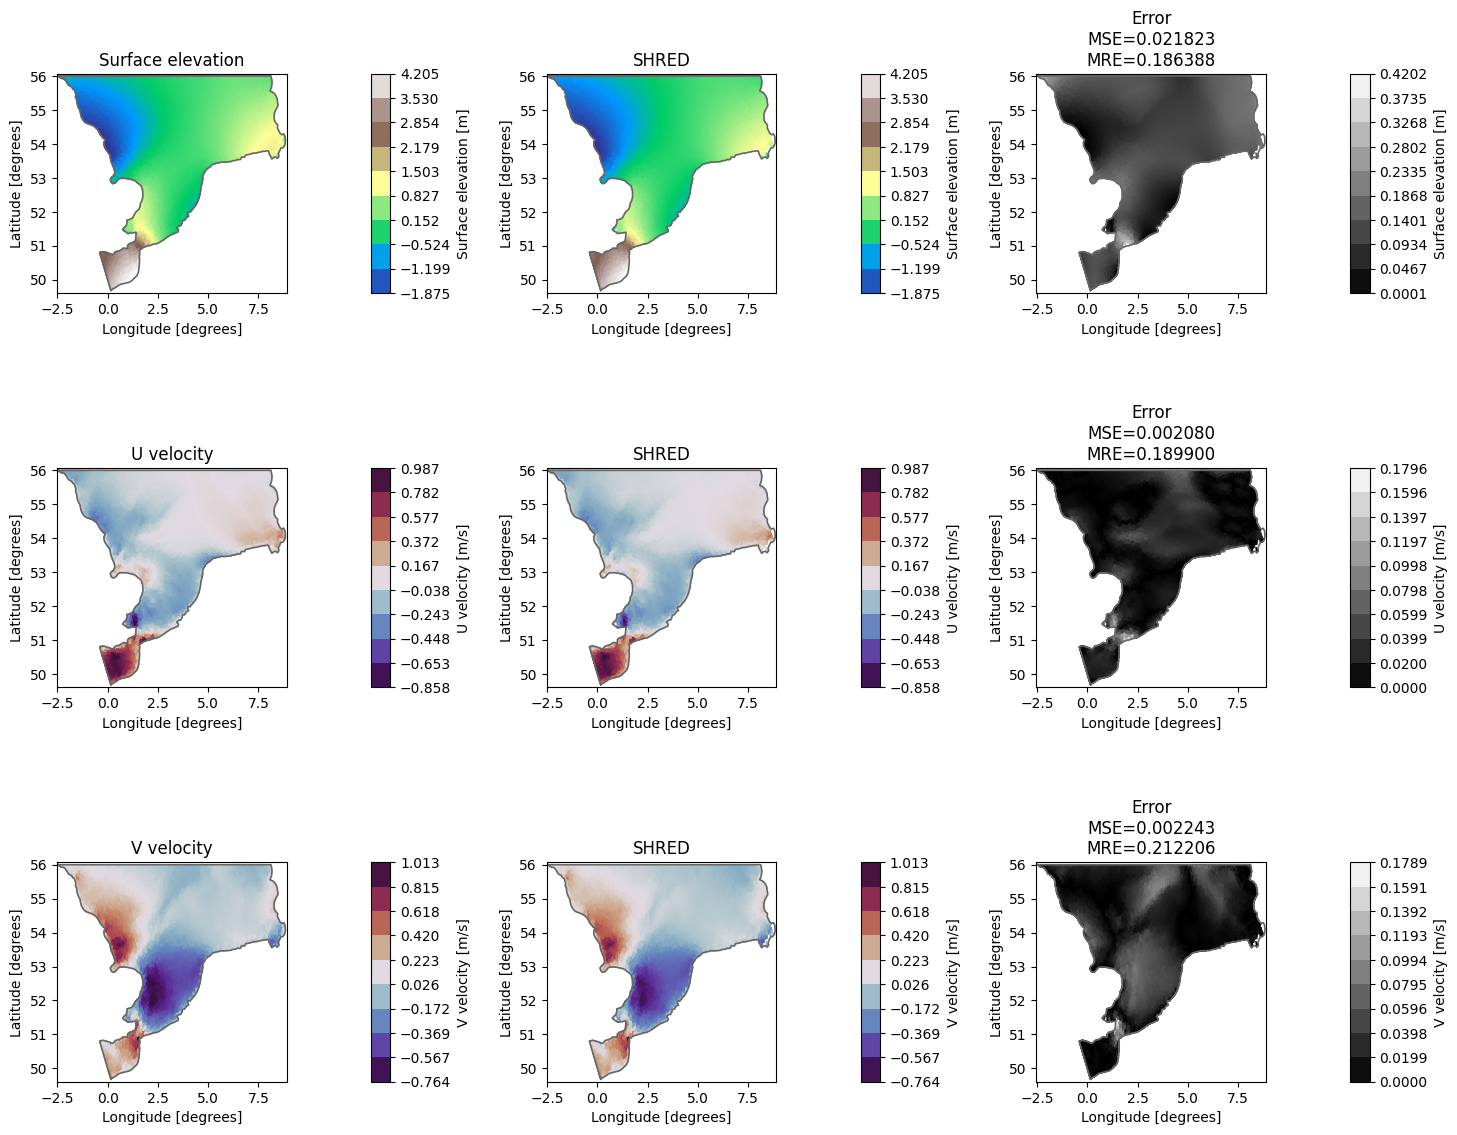

134204

In [31]:
# mSHRED RECONSTRUCTION

engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="2_B_attnGRUD_masking")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred, manager
gc.collect()

## Masking

In [32]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.85, val_size = 0.0, test_size = 0.15)

# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = 12, measurements = measurements)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, _, test_dataset = manager.prepare(verbose = True, masking_type="mask_data_random"); val_dataset = None

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 38987 

Residual energy of Surface elevation after keeping 12 modes: 0.1667 %
Residual energy of U velocity after keeping 40 modes: 0.1929 %
Residual energy of V velocity after keeping 68 modes: 0.1844 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 38987

Data shapes after preparation:
Train:	 torch.Size([26071, 24, 5]) -> torch.Size([26071, 120])
Val:	 torch.Size([0, 24, 5]) -> torch.Size([0, 120])
Test:	 torch.Size([4601, 24, 5]) -> torch.Size([4601, 120])

Input shape for the model: 5
Output shape for the model: 120


## Idea 3.0: TSHRED

Starting training...


Training: 100%|██████████| 250/250 [30:29<00:00,  7.32s/it, Train Loss=0.0047, LR=0.00e+00]

Training completed without validation set (early stopping disabled).


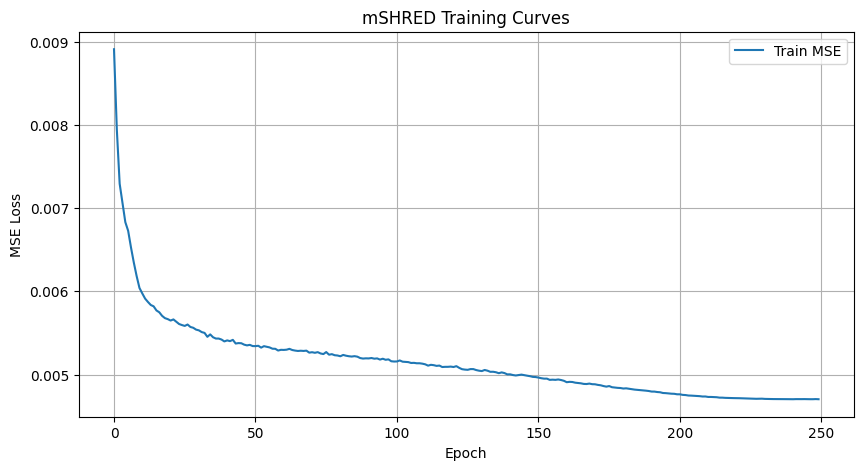

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004472,0.004213,0.133182,0.127428
4,(mSHRED): TR + MLP,(T.1.C) last value imputation for missing sensors,0.004390,0.004239,0.132071,0.128126
5,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004493,0.004284,0.133687,0.129290
6,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004537,0.004387,0.134571,0.131390
7,(mSHRED): TR + MLP,(3.0) TSHRED,0.004703,0.004226,0.136097,0.127925


In [33]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, _ = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=250,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=250,
    patience=60,
    verbose=True,
    masking_type= "mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
# validation curve disabled (no validation set)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset,masking_type= "mask_data")
# validation metrics disabled (no validation set)
test_mse, test_mre = evaluate(mshred, test_dataset,masking_type= "mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.0) TSHRED",
    "train-mse": float(train_mse),
    # val-mse disabled (no validation set),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    # val-mre disabled (no validation set),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_0_tshred.png


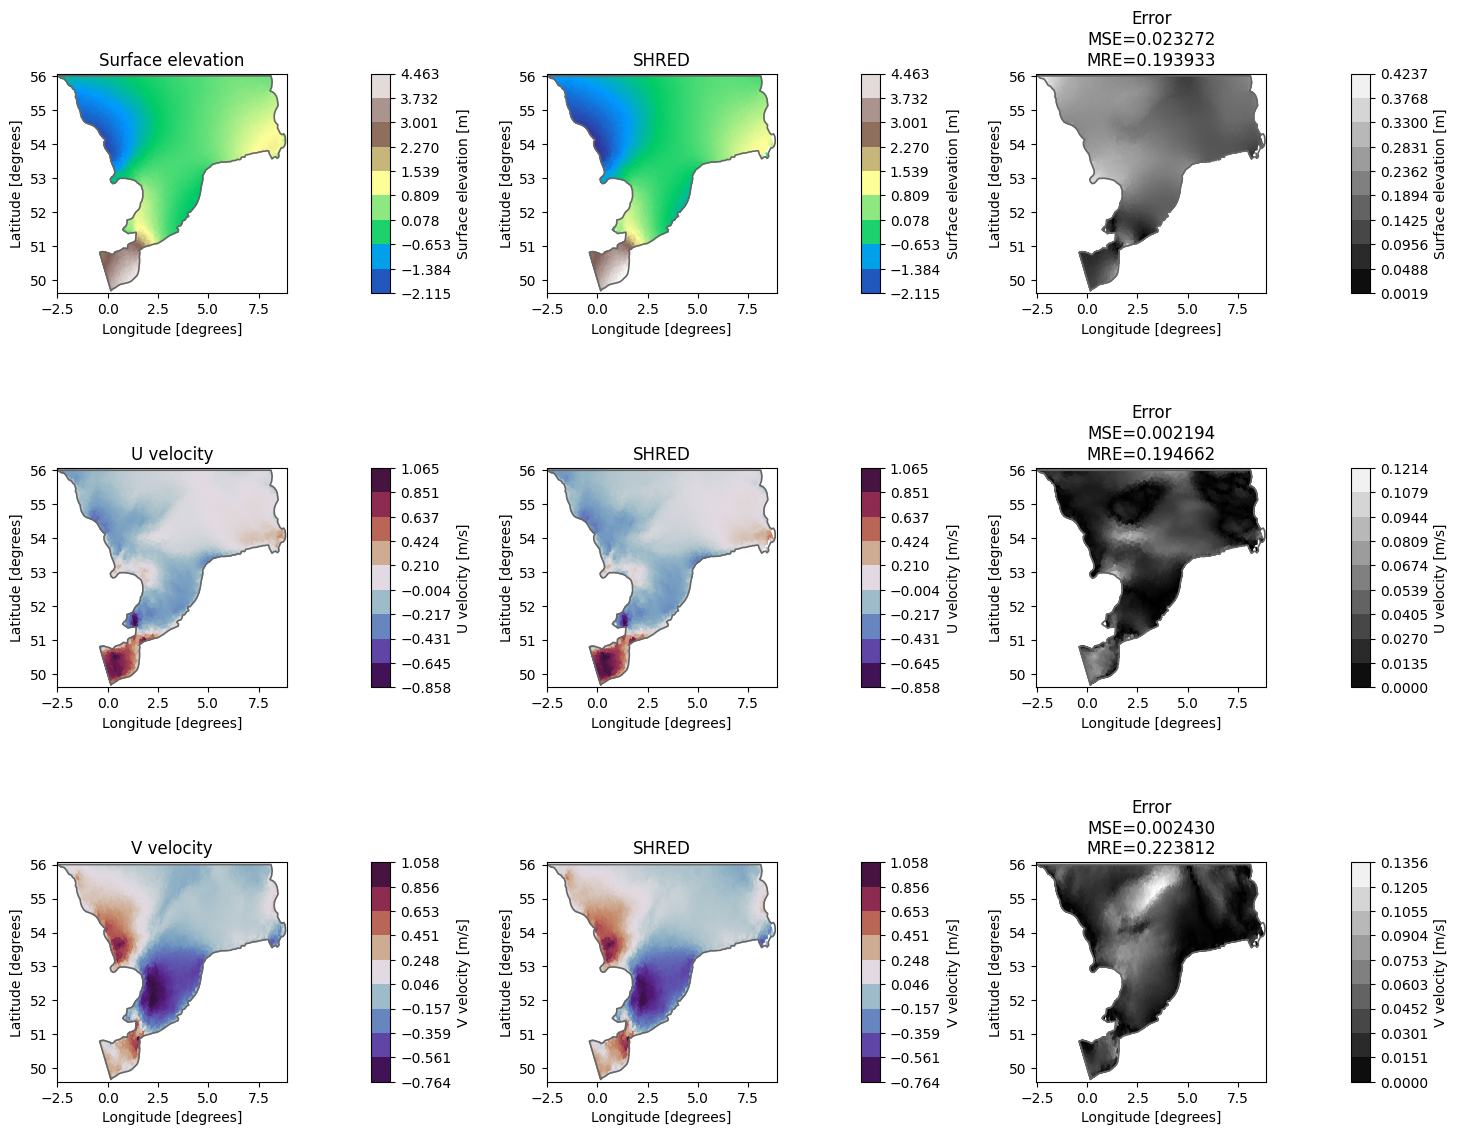

134274

In [34]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_0_tshred")

del engine, test_reconstruction, ds_shred, ds_error, mshred
gc.collect()

## Idea 3.A: Mask double channels

Starting training...


Training: 100%|██████████| 250/250 [30:49<00:00,  7.40s/it, Train Loss=0.0046, LR=0.00e+00]

Training completed without validation set (early stopping disabled).


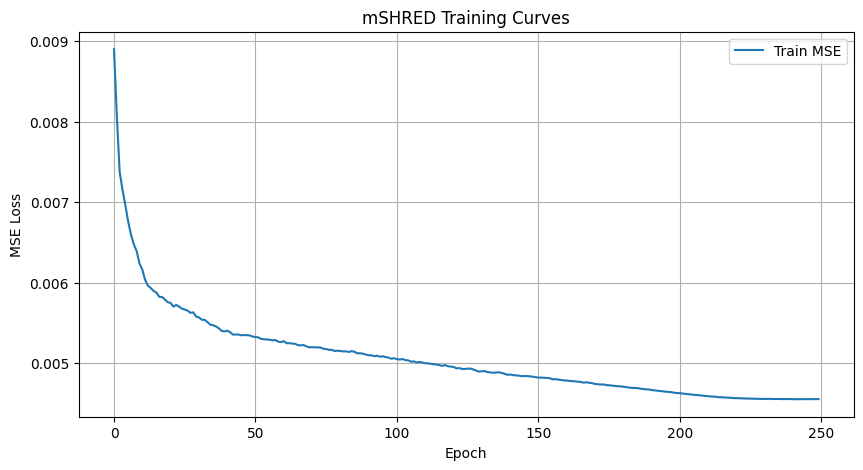

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004472,0.004213,0.133182,0.127428
4,(mSHRED): TR + MLP,(T.1.C) last value imputation for missing sensors,0.004390,0.004239,0.132071,0.128126
5,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004493,0.004284,0.133687,0.129290
6,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004537,0.004387,0.134571,0.131390
7,(mSHRED): TR + MLP,(3.0) TSHRED,0.004703,0.004226,0.136097,0.127925
8,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004551,0.004226,0.133876,0.127720


In [35]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, _ = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=250,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=250,
    patience=60,
    verbose=True,
    masking_type= "mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
# validation curve disabled (no validation set)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset,masking_type= "mask_data")
# validation metrics disabled (no validation set)
test_mse, test_mre = evaluate(mshred, test_dataset,masking_type= "mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.A) Mask double channels",
    "train-mse": float(train_mse),
    # val-mse disabled (no validation set),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    # val-mre disabled (no validation set),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_A_mask_double_channels.png


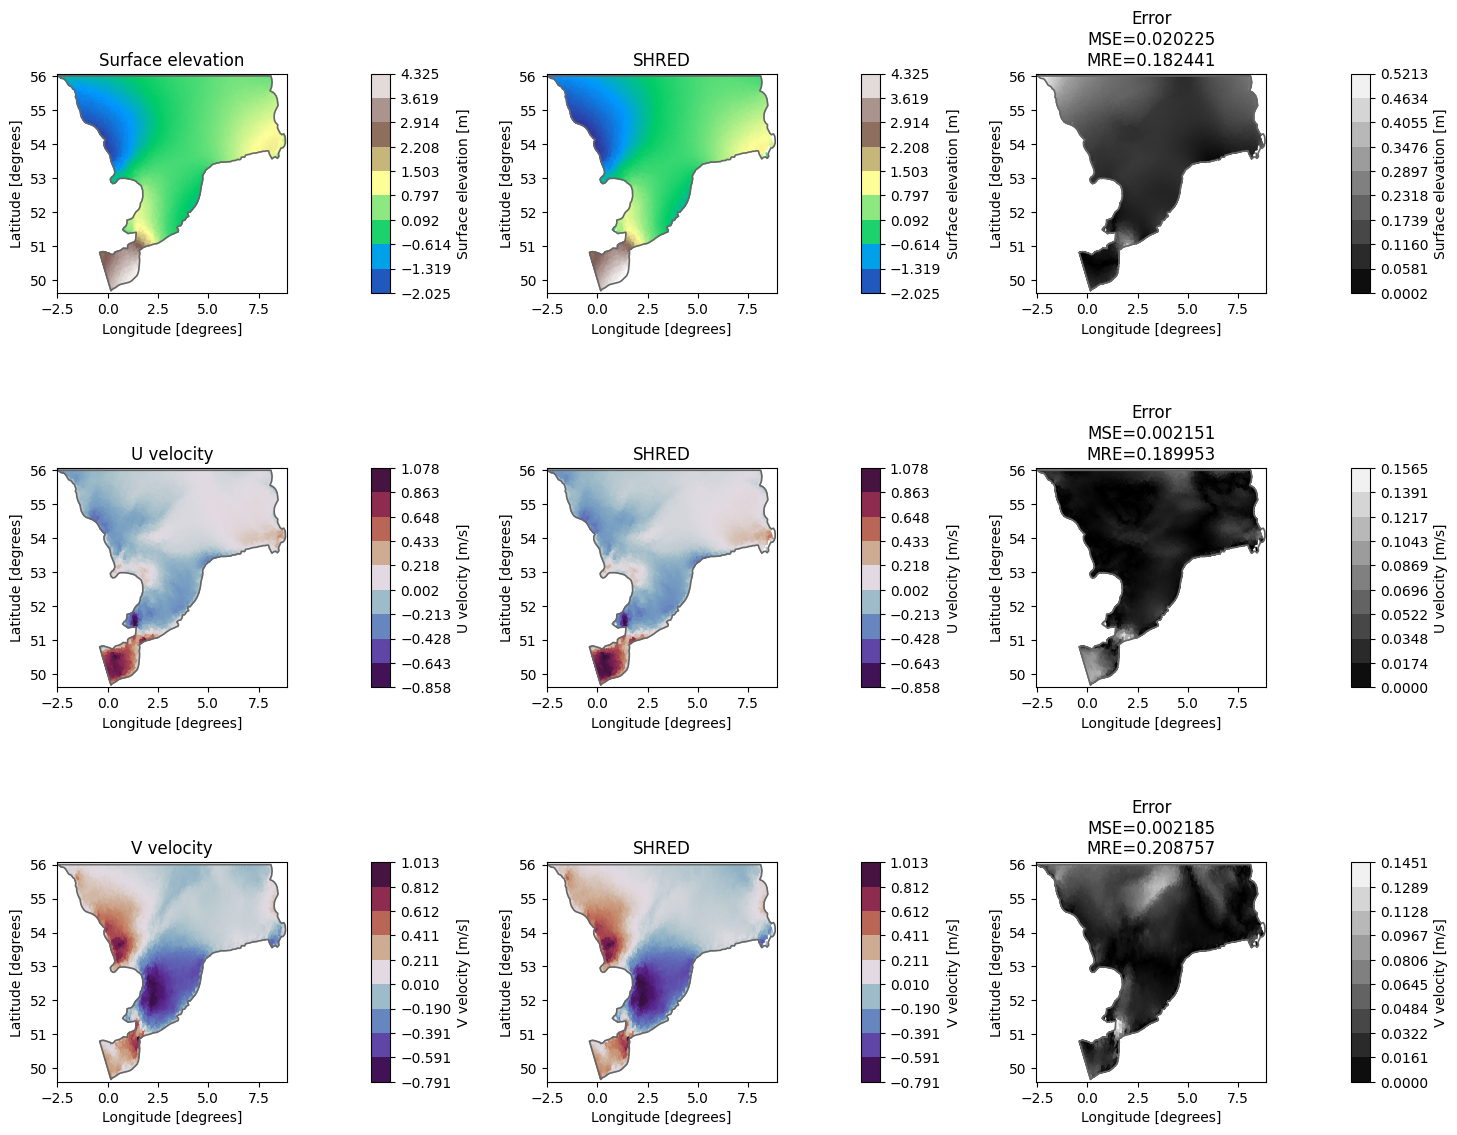

134672

In [36]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_A_mask_double_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred
gc.collect()

## Idea 3.B: Mask in the hidden space

Starting training...


Training: 100%|██████████| 250/250 [30:58<00:00,  7.43s/it, Train Loss=0.0045, LR=0.00e+00]

Training completed without validation set (early stopping disabled).


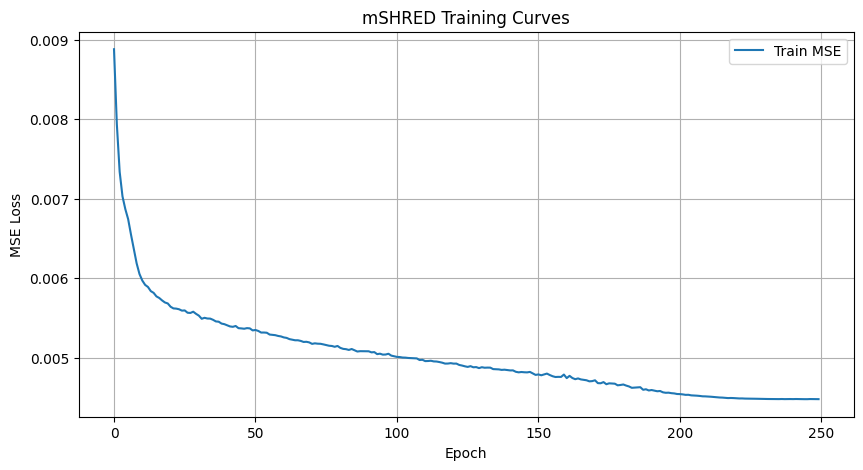

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004472,0.004213,0.133182,0.127428
4,(mSHRED): TR + MLP,(T.1.C) last value imputation for missing sensors,0.004390,0.004239,0.132071,0.128126
5,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004493,0.004284,0.133687,0.129290
6,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004537,0.004387,0.134571,0.131390
7,(mSHRED): TR + MLP,(3.0) TSHRED,0.004703,0.004226,0.136097,0.127925
8,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004551,0.004226,0.133876,0.127720
9,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004481,0.004173,0.133273,0.126826


In [37]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, _ = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=250,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=250,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
# validation curve disabled (no validation set)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
# validation metrics disabled (no validation set)
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.B) Mask the hidden state",
    "train-mse": float(train_mse),
    # val-mse disabled (no validation set),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    # val-mre disabled (no validation set),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_B_mask_hidden_state.png


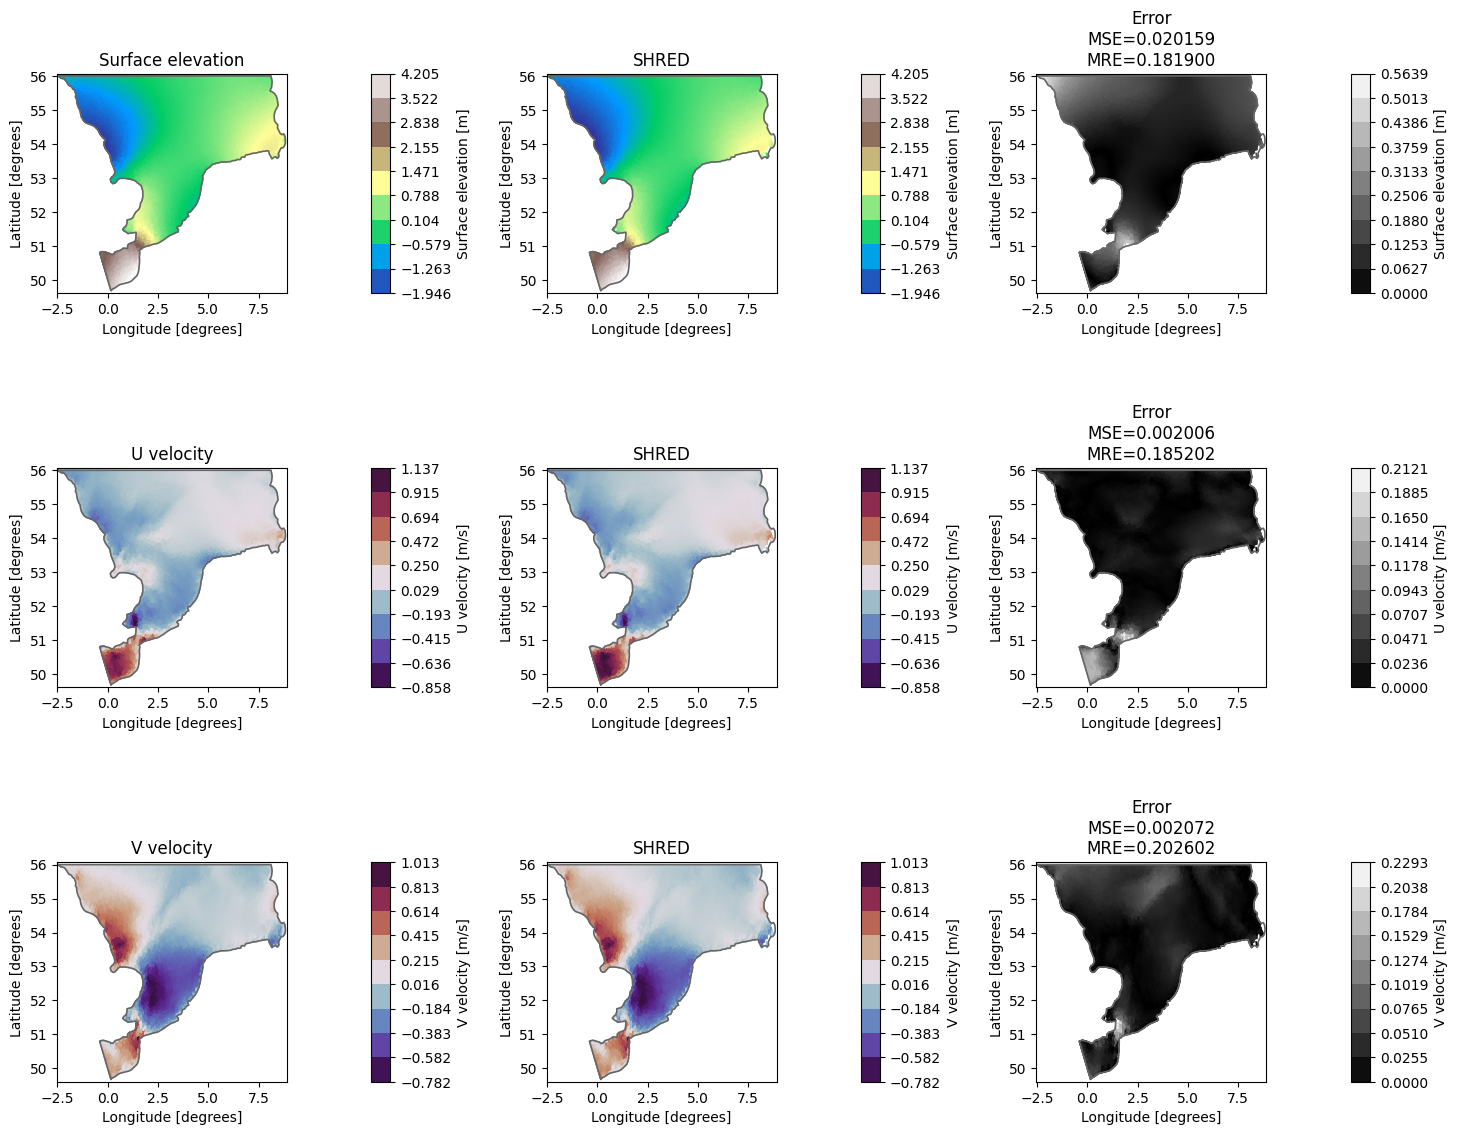

134485

In [38]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_B_mask_hidden_state")

del engine, test_reconstruction, ds_shred, ds_error, mshred
gc.collect()

## Idea 3.C: Mask in the attention block

Starting training...


Training: 100%|██████████| 250/250 [31:24<00:00,  7.54s/it, Train Loss=0.0047, LR=0.00e+00]

Training completed without validation set (early stopping disabled).


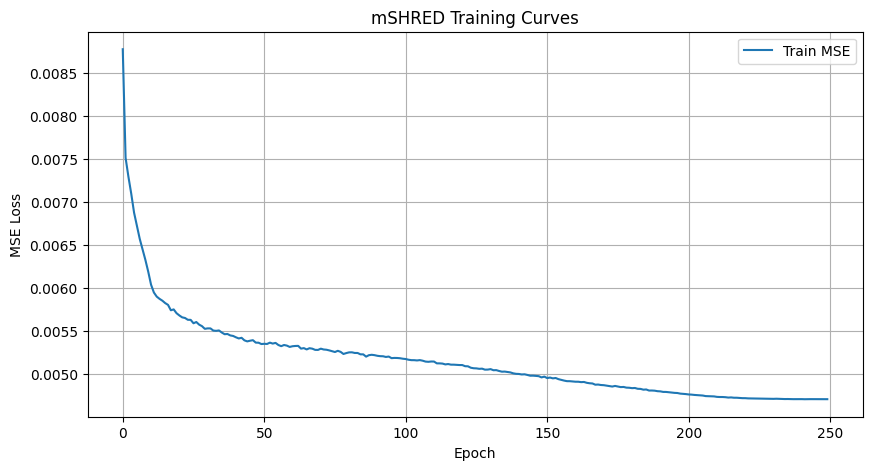

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004472,0.004213,0.133182,0.127428
4,(mSHRED): TR + MLP,(T.1.C) last value imputation for missing sensors,0.004390,0.004239,0.132071,0.128126
5,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004493,0.004284,0.133687,0.129290
6,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004537,0.004387,0.134571,0.131390
7,(mSHRED): TR + MLP,(3.0) TSHRED,0.004703,0.004226,0.136097,0.127925
8,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004551,0.004226,0.133876,0.127720
9,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004481,0.004173,0.133273,0.126826


In [39]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, _ = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=250,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=250,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
# validation curve disabled (no validation set)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
# validation metrics disabled (no validation set)
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.C) Mask in the attention block",
    "train-mse": float(train_mse),
    # val-mse disabled (no validation set),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    # val-mre disabled (no validation set),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_C_mask_attention_block.png


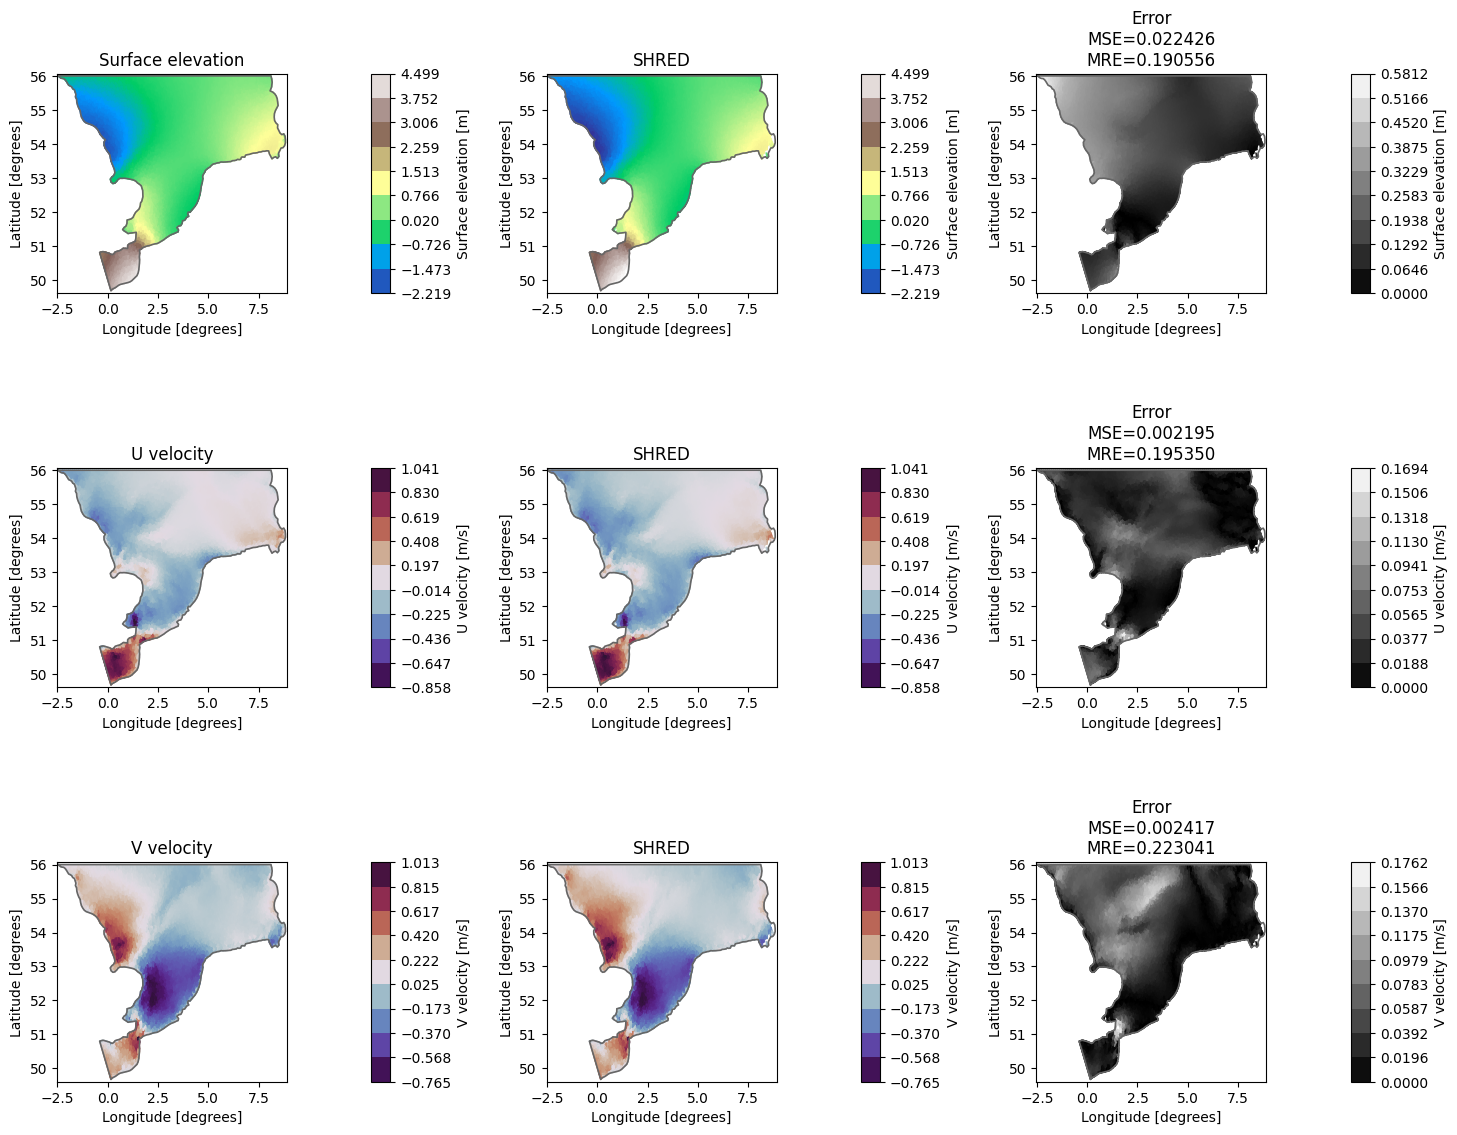

134642

In [40]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_C_mask_attention_block")

del engine, test_reconstruction, ds_shred, ds_error, mshred
gc.collect()

## Idea 3.D: Attention mask + double channels

Starting training...


Training: 100%|██████████| 250/250 [31:13<00:00,  7.49s/it, Train Loss=0.0046, LR=0.00e+00]

Training completed without validation set (early stopping disabled).


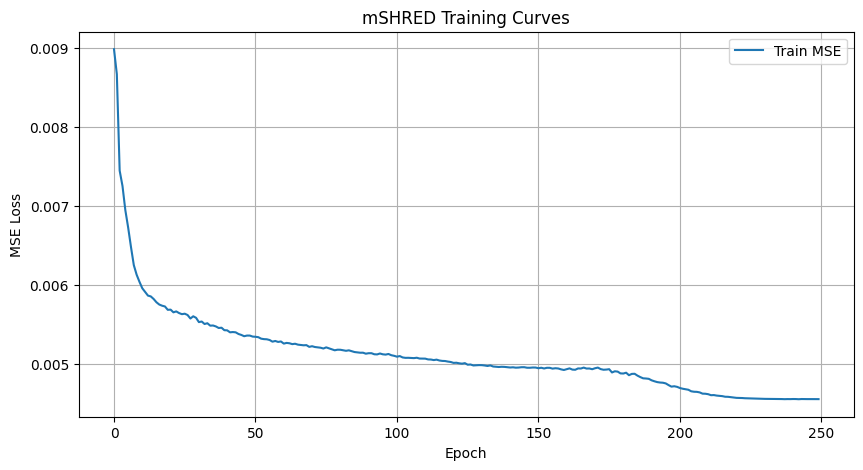

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004472,0.004213,0.133182,0.127428
4,(mSHRED): TR + MLP,(T.1.C) last value imputation for missing sensors,0.004390,0.004239,0.132071,0.128126
5,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004493,0.004284,0.133687,0.129290
6,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004537,0.004387,0.134571,0.131390
7,(mSHRED): TR + MLP,(3.0) TSHRED,0.004703,0.004226,0.136097,0.127925
8,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004551,0.004226,0.133876,0.127720
9,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004481,0.004173,0.133273,0.126826


In [41]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, _ = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=250,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=250,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
# validation curve disabled (no validation set)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
# validation metrics disabled (no validation set)
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.D) Double masking",
    "train-mse": float(train_mse),
    # val-mse disabled (no validation set),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    # val-mre disabled (no validation set),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_D_double_masking.png


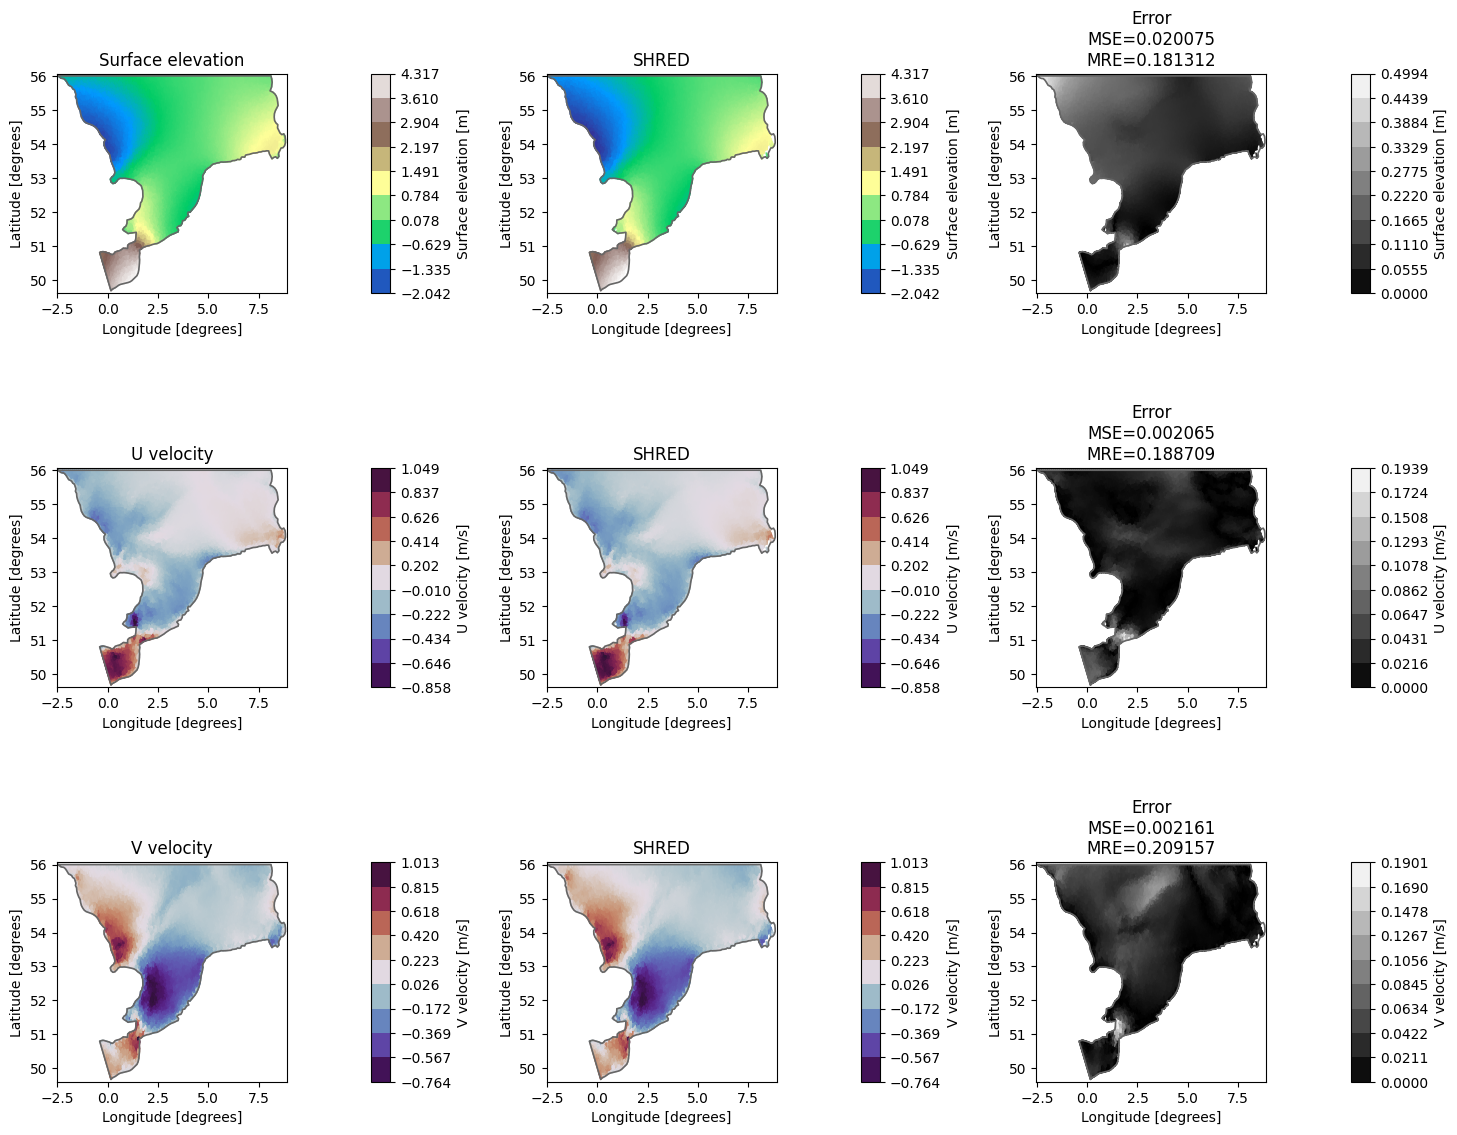

134594

In [42]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_D_double_masking")

del engine, test_reconstruction, ds_shred, ds_error, mshred
gc.collect()

## Idea 3.E: learn the mask in the softmax


Starting training...


Training: 100%|██████████| 250/250 [35:57<00:00,  8.63s/it, Train Loss=0.0045, LR=0.00e+00]

Training completed without validation set (early stopping disabled).


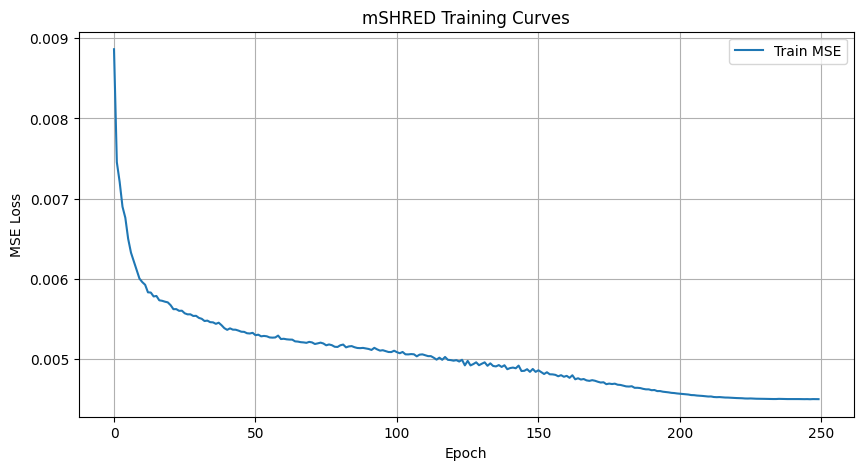

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004472,0.004213,0.133182,0.127428
4,(mSHRED): TR + MLP,(T.1.C) last value imputation for missing sensors,0.004390,0.004239,0.132071,0.128126
5,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004493,0.004284,0.133687,0.129290
6,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004537,0.004387,0.134571,0.131390
7,(mSHRED): TR + MLP,(3.0) TSHRED,0.004703,0.004226,0.136097,0.127925
8,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004551,0.004226,0.133876,0.127720
9,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004481,0.004173,0.133273,0.126826


In [43]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, _ = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=250,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=250,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
# validation curve disabled (no validation set)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
# validation metrics disabled (no validation set)
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.E) Transformer Learned mask",
    "train-mse": float(train_mse),
    # val-mse disabled (no validation set),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    # val-mre disabled (no validation set),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_D_learn_mask_softmax.png


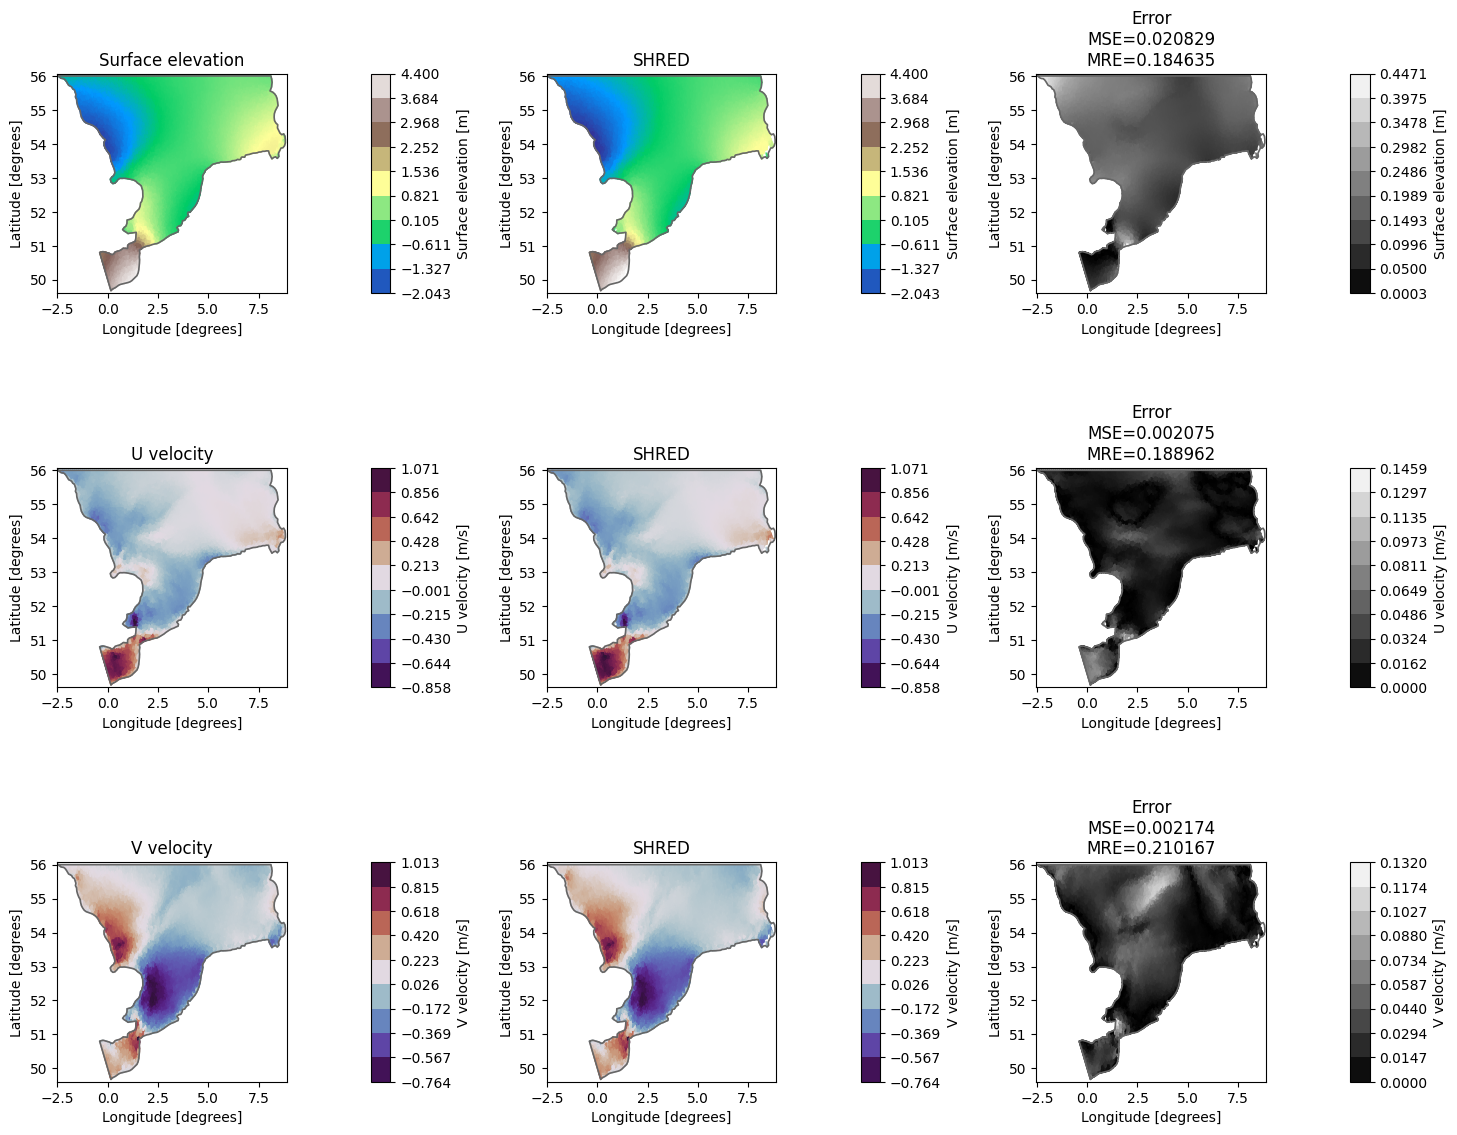

134642

In [44]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_D_learn_mask_softmax")

del engine, test_reconstruction, ds_shred, ds_error, mshred
gc.collect()

## Idea 3.F: Learned mask + double channels


Starting training...


Training: 100%|██████████| 250/250 [36:43<00:00,  8.81s/it, Train Loss=0.0046, LR=0.00e+00]

Training completed without validation set (early stopping disabled).


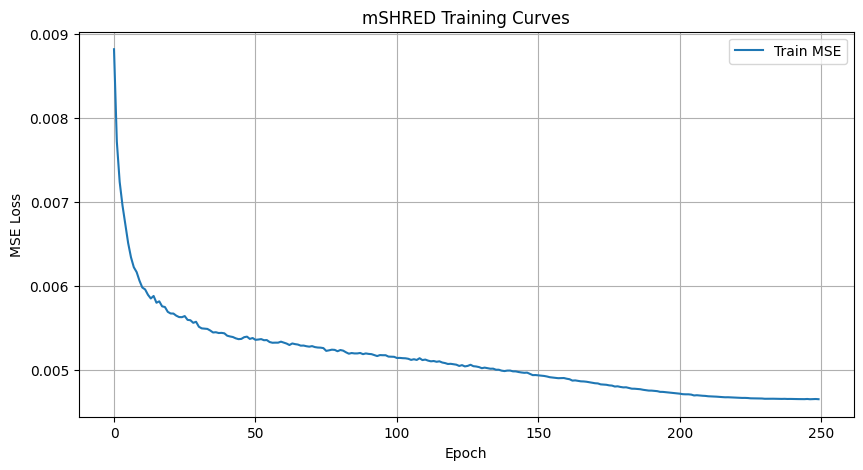

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004472,0.004213,0.133182,0.127428
4,(mSHRED): TR + MLP,(T.1.C) last value imputation for missing sensors,0.004390,0.004239,0.132071,0.128126
5,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004493,0.004284,0.133687,0.129290
6,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004537,0.004387,0.134571,0.131390
7,(mSHRED): TR + MLP,(3.0) TSHRED,0.004703,0.004226,0.136097,0.127925
8,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004551,0.004226,0.133876,0.127720
9,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004481,0.004173,0.133273,0.126826


In [45]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, _ = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=250,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=250,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
# validation curve disabled (no validation set)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
# validation metrics disabled (no validation set)
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.F) Transformer Learned mask + double channels",
    "train-mse": float(train_mse),
    # val-mse disabled (no validation set),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    # val-mre disabled (no validation set),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_F_learn_mask_double_channels.png


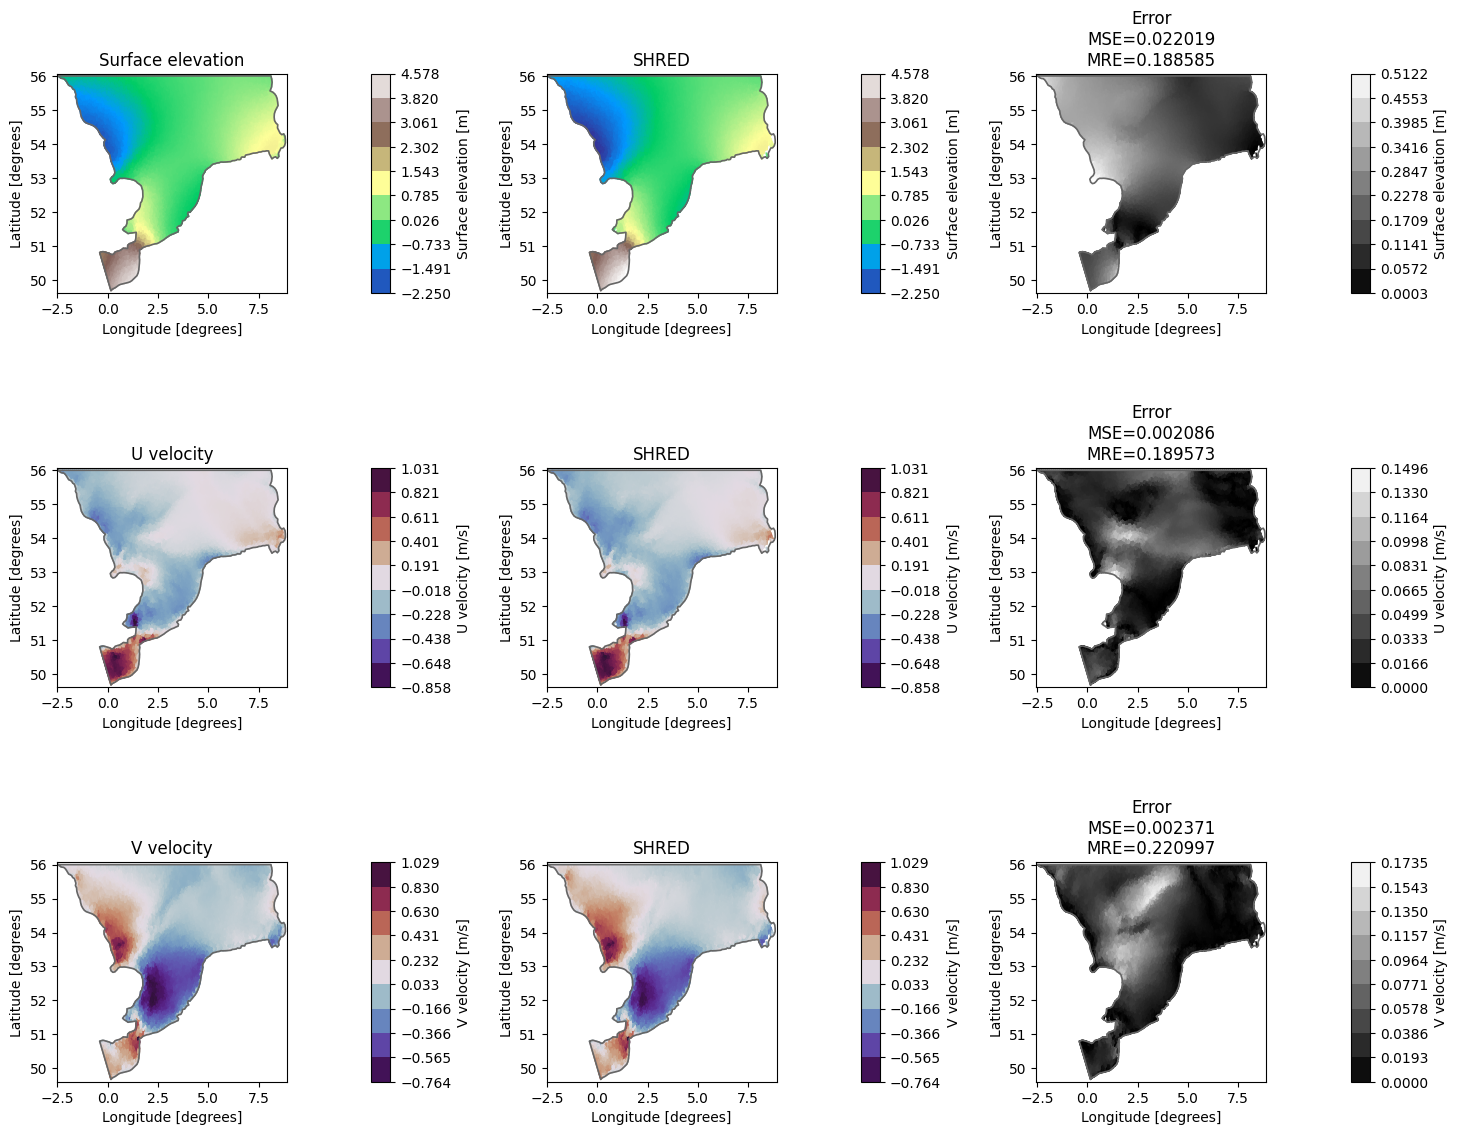

134642

In [46]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_F_learn_mask_double_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred
gc.collect()

## Results

In [47]:
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,test-mse,train-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.004748,0.004267,0.136903,0.128795
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004472,0.004213,0.133182,0.127428
4,(mSHRED): TR + MLP,(T.1.C) last value imputation for missing sensors,0.004390,0.004239,0.132071,0.128126
5,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.004493,0.004284,0.133687,0.129290
6,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004537,0.004387,0.134571,0.131390
7,(mSHRED): TR + MLP,(3.0) TSHRED,0.004703,0.004226,0.136097,0.127925
8,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004551,0.004226,0.133876,0.127720
9,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004481,0.004173,0.133273,0.126826


In [48]:
# order dataframe by test-mse
dataframe_errors = dataframe_errors.sort_values(by="test-mse")
display(dataframe_errors)

# order dataframe by test-mre
dataframe_errors = dataframe_errors.sort_values(by="test-mre")
display(dataframe_errors)

,model,type,train-mse,test-mse,train-mre,test-mre
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
12,(mSHRED): TR + MLP,(3.E) Transformer Learned mask,0.004504,0.004156,0.133608,0.126622
9,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004481,0.004173,0.133273,0.126826
13,(mSHRED): TR + MLP,(3.F) Transformer Learned mask + double channels,0.004649,0.004190,0.135365,0.127272
11,(mSHRED): TR + MLP,(3.D) Double masking,0.004555,0.004201,0.134310,0.127466
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004472,0.004213,0.133182,0.127428
10,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.004706,0.004213,0.136311,0.127700
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760
8,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004551,0.004226,0.133876,0.127720
7,(mSHRED): TR + MLP,(3.0) TSHRED,0.004703,0.004226,0.136097,0.127925


,model,type,train-mse,test-mse,train-mre,test-mre
12,(mSHRED): TR + MLP,(3.E) Transformer Learned mask,0.004504,0.004156,0.133608,0.126622
9,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.004481,0.004173,0.133273,0.126826
13,(mSHRED): TR + MLP,(3.F) Transformer Learned mask + double channels,0.004649,0.004190,0.135365,0.127272
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.004458,0.004138,0.132583,0.127280
3,(mSHRED): TR + MLP,(T.1.B) mean imputation for missing sensors,0.004472,0.004213,0.133182,0.127428
11,(mSHRED): TR + MLP,(3.D) Double masking,0.004555,0.004201,0.134310,0.127466
10,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.004706,0.004213,0.136311,0.127700
8,(mSHRED): TR + MLP,(3.A) Mask double channels,0.004551,0.004226,0.133876,0.127720
2,(mSHRED): TR + MLP,(T.1.A) median imputation for missing sensors,0.004455,0.004214,0.133022,0.127760
7,(mSHRED): TR + MLP,(3.0) TSHRED,0.004703,0.004226,0.136097,0.127925


## Run 1

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.0) only available sensors</td>
      <td>0.004735</td>
      <td>0.004224</td>
      <td>0.136562</td>
      <td>0.128031</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.0) only available sensors</td>
      <td>0.004547</td>
      <td>0.004139</td>
      <td>0.133680</td>
      <td>0.126824</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.A) median imputation for missing sensors</td>
      <td>0.004571</td>
      <td>0.004247</td>
      <td>0.134653</td>
      <td>0.128298</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.B) mean imputation for missing sensors</td>
      <td>0.004560</td>
      <td>0.004233</td>
      <td>0.134315</td>
      <td>0.127915</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.C) last value imputation for missing sensors</td>
      <td>0.004536</td>
      <td>0.004240</td>
      <td>0.133923</td>
      <td>0.128188</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): GRUD + CNN</td>
      <td>(2.A) GRUD masking</td>
      <td>0.004574</td>
      <td>0.004325</td>
      <td>0.135151</td>
      <td>0.130062</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): attnGRUD + CNN</td>
      <td>(2.B) GRUD masking</td>
      <td>0.004583</td>
      <td>0.004378</td>
      <td>0.134947</td>
      <td>0.131032</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.0) TSHRED</td>
      <td>0.004708</td>
      <td>0.004224</td>
      <td>0.136335</td>
      <td>0.127869</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.A) Mask double channels</td>
      <td>0.004732</td>
      <td>0.004273</td>
      <td>0.136659</td>
      <td>0.128735</td>
    </tr>
  </tbody>
</table>
</div>

## Run 2

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>12</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.E) Transformer Learned mask</td>
      <td>0.004504</td>
      <td>0.004156</td>
      <td>0.133608</td>
      <td>0.126622</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.B) Mask the hidden state</td>
      <td>0.004481</td>
      <td>0.004173</td>
      <td>0.133273</td>
      <td>0.126826</td>
    </tr>
    <tr>
      <th>13</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.F) Transformer Learned mask + double channels</td>
      <td>0.004649</td>
      <td>0.004190</td>
      <td>0.135365</td>
      <td>0.127272</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.0) only available sensors</td>
      <td>0.004458</td>
      <td>0.004138</td>
      <td>0.132583</td>
      <td>0.127280</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.B) mean imputation for missing sensors</td>
      <td>0.004472</td>
      <td>0.004213</td>
      <td>0.133182</td>
      <td>0.127428</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.D) Double masking</td>
      <td>0.004555</td>
      <td>0.004201</td>
      <td>0.134310</td>
      <td>0.127466</td>
    </tr>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.C) Mask in the attention block</td>
      <td>0.004706</td>
      <td>0.004213</td>
      <td>0.136311</td>
      <td>0.127700</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.A) Mask double channels</td>
      <td>0.004551</td>
      <td>0.004226</td>
      <td>0.133876</td>
      <td>0.127720</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.A) median imputation for missing sensors</td>
      <td>0.004455</td>
      <td>0.004214</td>
      <td>0.133022</td>
      <td>0.127760</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(3.0) TSHRED</td>
      <td>0.004703</td>
      <td>0.004226</td>
      <td>0.136097</td>
      <td>0.127925</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.1.C) last value imputation for missing sensors</td>
      <td>0.004390</td>
      <td>0.004239</td>
      <td>0.132071</td>
      <td>0.128126</td>
    </tr>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR + MLP</td>
      <td>(T.0) only available sensors</td>
      <td>0.004748</td>
      <td>0.004267</td>
      <td>0.136903</td>
      <td>0.128795</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): GRUD + CNN</td>
      <td>(2.A) GRUD masking</td>
      <td>0.004493</td>
      <td>0.004284</td>
      <td>0.133687</td>
      <td>0.129290</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): attnGRUD + CNN</td>
      <td>(2.B) GRUD masking</td>
      <td>0.004537</td>
      <td>0.004387</td>
      <td>0.134571</td>
      <td>0.131390</td>
    </tr>
  </tbody>
</table>
</div>